# Exploring Global Video Game Sales

## Project Overview

In this project we explore and analyse a dataset of global video game sales to uncover
trends and insights in the gaming industry.

The dataset contains information on video games released across various **platforms**,
**genres**, and **publishers**, along with their sales in different global regions
(North America, Europe, Japan, and Other).

### Workflow

| Part | Description |
|------|-------------|
| **I** | Data Cleaning & Preparation |
| **II** | Exploratory Data Analysis (EDA) |
| **III** | Visualization & Storytelling |

### Datasets

| File | Rows | Description |
|------|------|-------------|
| `data/vgsales.csv` | 16 598 | Classic VGChartz scrape (Rank, Name, Platform, Year, Genre, Publisher, regional & global sales) |
| `data/vgchartz-2024.csv` | 64 016 | Updated 2024 VGChartz scrape (includes developer, critic score, release date) |

---
## Environment Setup

Import all required libraries and configure notebook-wide settings.

In [1]:
# ── Standard libraries ──────────────────────────────────────────────
import warnings
warnings.filterwarnings("ignore")

# ── Data manipulation ──────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualization ─────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# ── Display settings ──────────────────────────────────────────────
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print("Libraries loaded successfully.")
print(f"pandas {pd.__version__}  •  numpy {np.__version__}")
print(f"matplotlib {plt.matplotlib.__version__}  •  seaborn {sns.__version__}")

Libraries loaded successfully.
pandas 3.0.6  •  numpy 2.5.3
matplotlib 3.11.2  •  seaborn 0.13.2


---
## Part I — Data Cleaning & Preparation

### 1.1 Load the Dataset & Inspect Its Structure

In [2]:
# ── Load primary dataset ──────────────────────────────────────────
df = pd.read_csv("data/vgsales.csv")

print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns\n")
df.info()

Shape: 16,598 rows × 11 columns

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.4 MB


In [3]:
# ── First rows ────────────────────────────────────────────────────
df.head(10)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.00,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.00,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.00,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.00,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.00,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
5,6,Tetris,GB,1989.00,Puzzle,Nintendo,23.20,2.26,4.22,0.58,30.26
6,7,New Super Mario Bros.,DS,2006.00,Platform,Nintendo,11.38,9.23,6.50,2.90,30.01
7,8,Wii Play,Wii,2006.00,Misc,Nintendo,14.03,9.20,2.93,2.85,29.02
8,9,New Super Mario Bros. Wii,Wii,2009.00,Platform,Nintendo,14.59,7.06,4.70,2.26,28.62
9,10,Duck Hunt,NES,1984.00,Shooter,Nintendo,26.93,0.63,0.28,0.47,28.31


In [4]:
# ── Last rows ─────────────────────────────────────────────────────
df.tail(5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.00,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.00,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.00,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.00,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01
16597,16600,Spirits & Spells,GBA,2003.00,Platform,Wanadoo,0.01,0.00,0.00,0.00,0.01


In [5]:
# ── Quick descriptive stats ───────────────────────────────────────
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.00,16327.00,16598.00,16598.00,16598.00,16598.00,16598.00
mean,8300.61,2006.41,0.26,0.15,0.08,0.05,0.54
std,4791.85,5.83,0.82,0.51,0.31,0.19,1.56
min,1.00,1980.00,0.00,0.00,0.00,0.00,0.01
25%,4151.25,2003.00,0.00,0.00,0.00,0.00,0.06
50%,8300.50,2007.00,0.08,0.02,0.00,0.01,0.17
75%,12449.75,2010.00,0.24,0.11,0.04,0.04,0.47
max,16600.00,2020.00,41.49,29.02,10.22,10.57,82.74


In [6]:
# ── Column data types ────────────────────────────────────────────
df.dtypes

Rank              int64
Name                str
Platform            str
Year            float64
Genre               str
Publisher           str
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

### 1.2 Check for Missing & Inconsistent Values

In [7]:
# ── Missing values summary ────────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_pct
}).sort_values("Missing Count", ascending=False)

print("Missing values per column:\n")
missing_report[missing_report["Missing Count"] > 0]

Missing values per column:



,Missing Count,Missing %
Year,271,1.63
Publisher,58,0.35


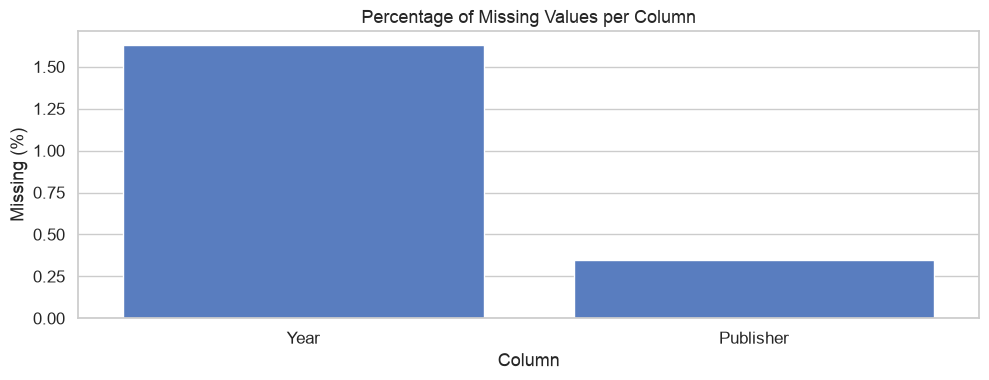

In [8]:
# ── Visualize missingness ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
cols_with_missing = missing_report[missing_report["Missing Count"] > 0].index
sns.barplot(x=cols_with_missing, y=missing_report.loc[cols_with_missing, "Missing %"], ax=ax)
ax.set_title("Percentage of Missing Values per Column")
ax.set_ylabel("Missing (%)")
ax.set_xlabel("Column")
plt.tight_layout()
plt.show()

### 1.3 Handle Missing Data

In [9]:
# ── Year column: inspect missing ──────────────────────────────────
print(f"Year — missing: {df['Year'].isnull().sum()}")
print(f"Year dtype before cleaning: {df['Year'].dtype}")

# Strategy: drop rows where Year is missing (small fraction).
# Year is critical for time-based analysis; imputation would introduce bias.
df = df.dropna(subset=["Year"])
print(f"\nRows after dropping missing Year: {len(df):,}")

Year — missing: 271
Year dtype before cleaning: float64

Rows after dropping missing Year: 16,327


In [10]:
# ── Publisher column: inspect missing ─────────────────────────────
print(f"Publisher — missing: {df['Publisher'].isnull().sum()}")

# Strategy: fill with 'Unknown' — dropping would lose sales data.
df["Publisher"] = df["Publisher"].fillna("Unknown")
print(f"Publisher — missing after fill: {df['Publisher'].isnull().sum()}")

Publisher — missing: 36
Publisher — missing after fill: 0


In [11]:
# ── Final missing check ───────────────────────────────────────────
print("Remaining missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
if df.isnull().sum().sum() == 0:
    print("✅ No missing values remain.")

Remaining missing values:
Series([], dtype: int64)
✅ No missing values remain.


### 1.4 Ensure Appropriate Data Types

In [12]:
# ── Convert Year to integer ───────────────────────────────────────
df["Year"] = df["Year"].astype(int)

# ── Verify sales columns are numeric ──────────────────────────────
sales_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]
for col in sales_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Data types after conversion:\n")
print(df.dtypes)

Data types after conversion:

Rank              int64
Name                str
Platform            str
Year              int64
Genre               str
Publisher           str
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object


### 1.5 Check for & Remove Duplicates

In [13]:
# ── Duplicates ────────────────────────────────────────────────────
dup_count = df.duplicated().sum()
print(f"Duplicate rows found: {dup_count}")

if dup_count > 0:
    df = df.drop_duplicates()
    print(f"Rows after dedup: {len(df):,}")
else:
    print("✅ No duplicates to remove.")

# ── Reset index after all cleaning ────────────────────────────────
df = df.reset_index(drop=True)
print(f"\nFinal cleaned dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")

Duplicate rows found: 0
✅ No duplicates to remove.

Final cleaned dataset: 16,327 rows × 11 columns


### 1.6 Cleaned Dataset Summary

In [14]:
# ── Final overview of the cleaned DataFrame ──────────────────────
print("=" * 60)
print("CLEANED DATASET SUMMARY")
print("=" * 60)
df.info()
print()
df.describe()

CLEANED DATASET SUMMARY
<class 'pandas.DataFrame'>
RangeIndex: 16327 entries, 0 to 16326
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16327 non-null  int64  
 1   Name          16327 non-null  str    
 2   Platform      16327 non-null  str    
 3   Year          16327 non-null  int64  
 4   Genre         16327 non-null  str    
 5   Publisher     16327 non-null  str    
 6   NA_Sales      16327 non-null  float64
 7   EU_Sales      16327 non-null  float64
 8   JP_Sales      16327 non-null  float64
 9   Other_Sales   16327 non-null  float64
 10  Global_Sales  16327 non-null  float64
dtypes: float64(5), int64(2), str(4)
memory usage: 1.4 MB



,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16327.00,16327.00,16327.00,16327.00,16327.00,16327.00,16327.00
mean,8292.87,2006.41,0.27,0.15,0.08,0.05,0.54
std,4792.67,5.83,0.82,0.51,0.31,0.19,1.57
min,1.00,1980.00,0.00,0.00,0.00,0.00,0.01
25%,4136.50,2003.00,0.00,0.00,0.00,0.00,0.06
50%,8295.00,2007.00,0.08,0.02,0.00,0.01,0.17
75%,12441.50,2010.00,0.24,0.11,0.04,0.04,0.48
max,16600.00,2020.00,41.49,29.02,10.22,10.57,82.74


---
## Part II — Exploratory Data Analysis (EDA)

### 2.1 Descriptive Statistics

Compute key statistics for all numerical variables and identify standout games.

In [15]:
# ── Key descriptive statistics for numerical columns ─────────────
numerical_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]

stats = df[numerical_cols].agg(["count", "mean", "median", "std", "min", "max", "skew", "kurtosis"])
stats.index.name = "Statistic"

print("Descriptive Statistics for Sales Columns (in millions USD):\n")
stats

Descriptive Statistics for Sales Columns (in millions USD):



,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
Statistic,,,,,
count,16327.00,16327.00,16327.00,16327.00,16327.00
mean,0.27,0.15,0.08,0.05,0.54
median,0.08,0.02,0.00,0.01,0.17
std,0.82,0.51,0.31,0.19,1.57
min,0.00,0.00,0.00,0.00,0.01
max,41.49,29.02,10.22,10.57,82.74
skew,18.76,18.79,11.14,24.13,17.32
kurtosis,644.15,747.97,191.61,1014.01,597.18


#### Top 10 Best-Selling Games Globally

In [16]:
# ── Top 10 best-selling games globally ───────────────────────────
top10 = (
    df.nlargest(10, "Global_Sales")
      [["Rank", "Name", "Platform", "Year", "Genre", "Publisher",
        "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]]
      .reset_index(drop=True)
)
top10.index = top10.index + 1  # 1-based ranking
top10.index.name = "#"

print("Top 10 Best-Selling Video Games (Global Sales, millions USD):\n")
top10

Top 10 Best-Selling Video Games (Global Sales, millions USD):



,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
#,,,,,,,,,,,
1,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
2,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
3,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
4,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
5,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
6,6,Tetris,GB,1989,Puzzle,Nintendo,23.20,2.26,4.22,0.58,30.26
7,7,New Super Mario Bros.,DS,2006,Platform,Nintendo,11.38,9.23,6.50,2.90,30.01
8,8,Wii Play,Wii,2006,Misc,Nintendo,14.03,9.20,2.93,2.85,29.02
9,9,New Super Mario Bros. Wii,Wii,2009,Platform,Nintendo,14.59,7.06,4.70,2.26,28.62


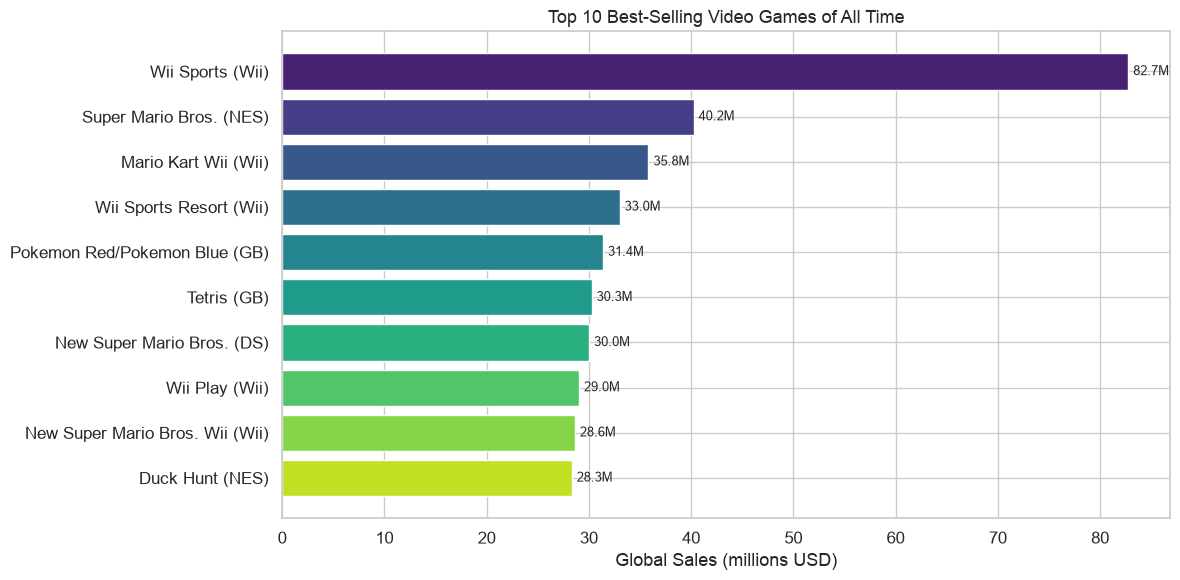

In [17]:
# ── Visualize top 10 games ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

colors = sns.color_palette("viridis", n_colors=10)
bars = ax.barh(
    top10["Name"] + " (" + top10["Platform"] + ")",
    top10["Global_Sales"],
    color=colors
)
ax.invert_yaxis()
ax.set_xlabel("Global Sales (millions USD)")
ax.set_title("Top 10 Best-Selling Video Games of All Time")

# Add value labels
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}M", va="center", fontsize=9)

plt.tight_layout()
plt.show()

#### Distribution of Global Sales

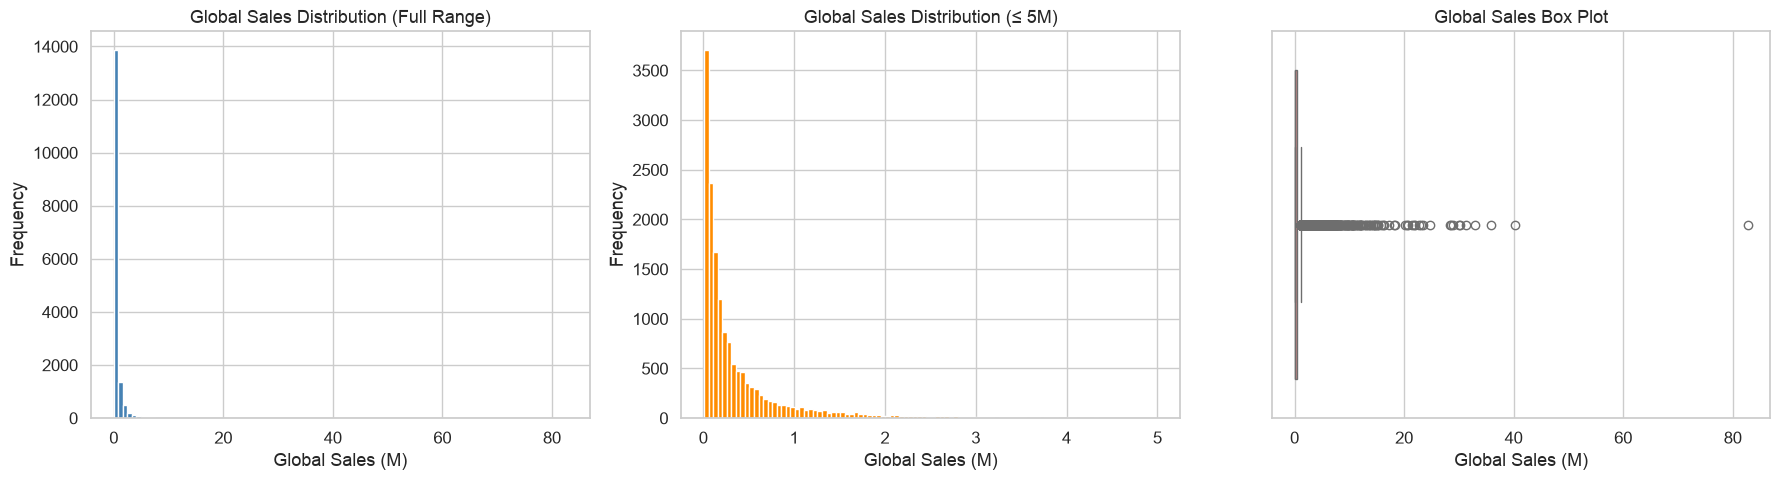

In [18]:
# ── Distribution of Global Sales ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Histogram (full range)
axes[0].hist(df["Global_Sales"], bins=100, color="steelblue", edgecolor="white")
axes[0].set_title("Global Sales Distribution (Full Range)")
axes[0].set_xlabel("Global Sales (M)")
axes[0].set_ylabel("Frequency")

# 2) Histogram (zoomed: sales ≤ 5M — where the bulk of data lives)
axes[1].hist(df[df["Global_Sales"] <= 5]["Global_Sales"], bins=100,
             color="darkorange", edgecolor="white")
axes[1].set_title("Global Sales Distribution (≤ 5M)")
axes[1].set_xlabel("Global Sales (M)")
axes[1].set_ylabel("Frequency")

# 3) Box plot
sns.boxplot(x=df["Global_Sales"], ax=axes[2], color="lightcoral")
axes[2].set_title("Global Sales Box Plot")
axes[2].set_xlabel("Global Sales (M)")

plt.tight_layout()
plt.show()

In [19]:
# ── Skewness & Outlier analysis ───────────────────────────────────
skew_val = df["Global_Sales"].skew()
kurt_val = df["Global_Sales"].kurtosis()

q1 = df["Global_Sales"].quantile(0.25)
q3 = df["Global_Sales"].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outliers = df[df["Global_Sales"] > upper_fence]

print("Global Sales Distribution Analysis")
print("=" * 45)
print(f"Skewness          : {skew_val:.2f}  (highly right-skewed)")
print(f"Kurtosis          : {kurt_val:.2f}  (heavy-tailed)")
print(f"IQR               : {iqr:.2f}M")
print(f"Upper fence (Q3+1.5×IQR): {upper_fence:.2f}M")
print(f"Outliers (>{upper_fence:.2f}M) : {len(outliers):,} games ({len(outliers)/len(df)*100:.1f}%)")
print(f"\nMedian sales      : {df['Global_Sales'].median():.2f}M")
print(f"Mean  sales       : {df['Global_Sales'].mean():.2f}M")
print(f"Max   sales       : {df['Global_Sales'].max():.2f}M")

Global Sales Distribution Analysis
Skewness          : 17.32  (highly right-skewed)
Kurtosis          : 597.18  (heavy-tailed)
IQR               : 0.42M
Upper fence (Q3+1.5×IQR): 1.11M
Outliers (>1.11M) : 1,827 games (11.2%)

Median sales      : 0.17M
Mean  sales       : 0.54M
Max   sales       : 82.74M


In [20]:
# ── Regional sales breakdown ──────────────────────────────────────
region_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
region_totals = df[region_cols].sum()
region_pct = (region_totals / region_totals.sum() * 100).round(1)

region_summary = pd.DataFrame({
    "Total Sales (M)": region_totals.round(2),
    "Share (%)": region_pct
})
region_summary.index = ["North America", "Europe", "Japan", "Other"]

print("Regional Sales Breakdown:\n")
print(region_summary)
print(f"\nTotal global sales: {df['Global_Sales'].sum():,.2f}M")

Regional Sales Breakdown:

               Total Sales (M)  Share (%)
North America          4333.43      49.20
Europe                 2409.12      27.30
Japan                  1284.30      14.60
Other                   789.01       8.90

Total global sales: 8,820.36M


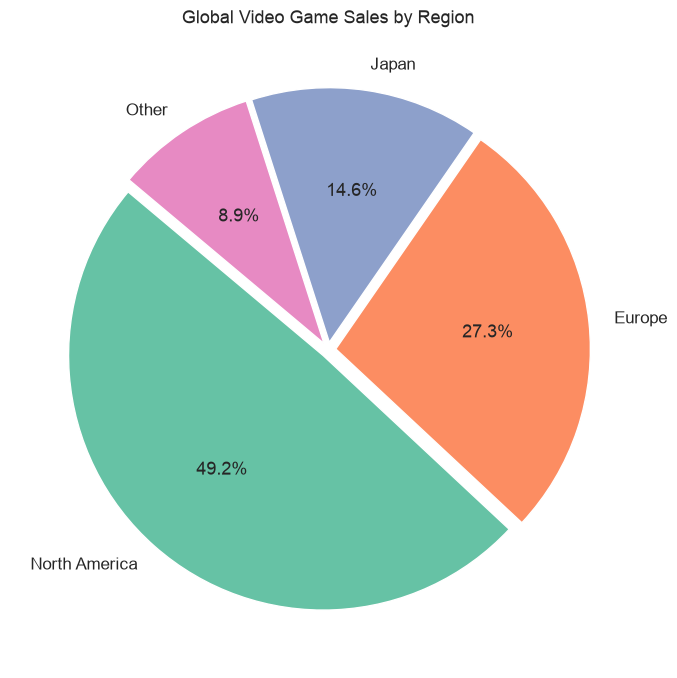

In [21]:
# ── Regional share pie chart ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    region_totals,
    labels=["North America", "Europe", "Japan", "Other"],
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("Set2", 4),
    explode=(0.03, 0.03, 0.03, 0.03)
)
ax.set_title("Global Video Game Sales by Region")
plt.tight_layout()
plt.show()

#### Key Takeaways — Descriptive Statistics

| Insight | Detail |
|---------|--------|
| **Highly skewed** | The vast majority of games sell very little; a small number of mega-hits dominate total sales. Mean ≫ Median confirms heavy right skew. |
| **Outliers are real** | Hundreds of games exceed the IQR-based upper fence — these are genuine blockbusters, not data errors. |
| **Nintendo dominance** | Nintendo titles occupy most of the top 10, led by *Wii Sports* at 82.74 M. |
| **Regional concentration** | North America alone accounts for the largest share of global sales, followed by Europe, Japan, and Other. |
| **Japan is niche** | Japan's total sales are significantly lower than NA/EU, but as we'll see later, certain genres over-index there. |

---
### 2.2 Trends Over Time

Analyze how the number of game releases and global sales have evolved year by year.

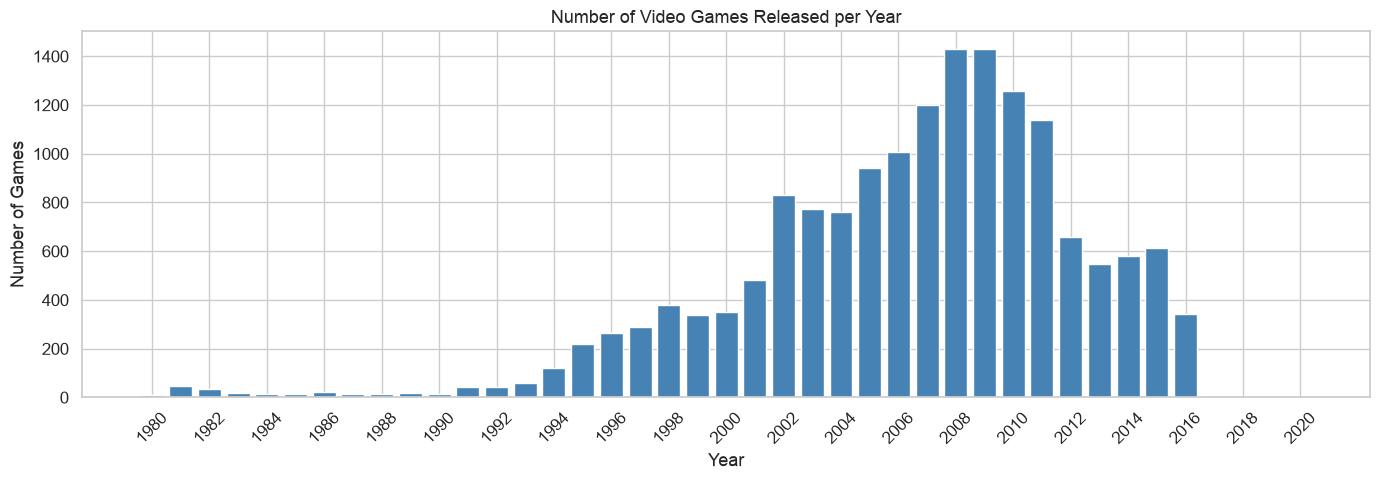


Peak year for releases: 2009 with 1,431 games


In [22]:
# ── Number of games released per year ────────────────────────────
games_per_year = df.groupby("Year").size().reset_index(name="Game_Count")

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(games_per_year["Year"], games_per_year["Game_Count"],
       color="steelblue", edgecolor="white", width=0.8)
ax.set_title("Number of Video Games Released per Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Games")
ax.set_xticks(range(int(games_per_year["Year"].min()), int(games_per_year["Year"].max()) + 1, 2))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

peak_year = games_per_year.loc[games_per_year["Game_Count"].idxmax()]
print(f"\nPeak year for releases: {int(peak_year['Year'])} with {peak_year['Game_Count']:,} games")

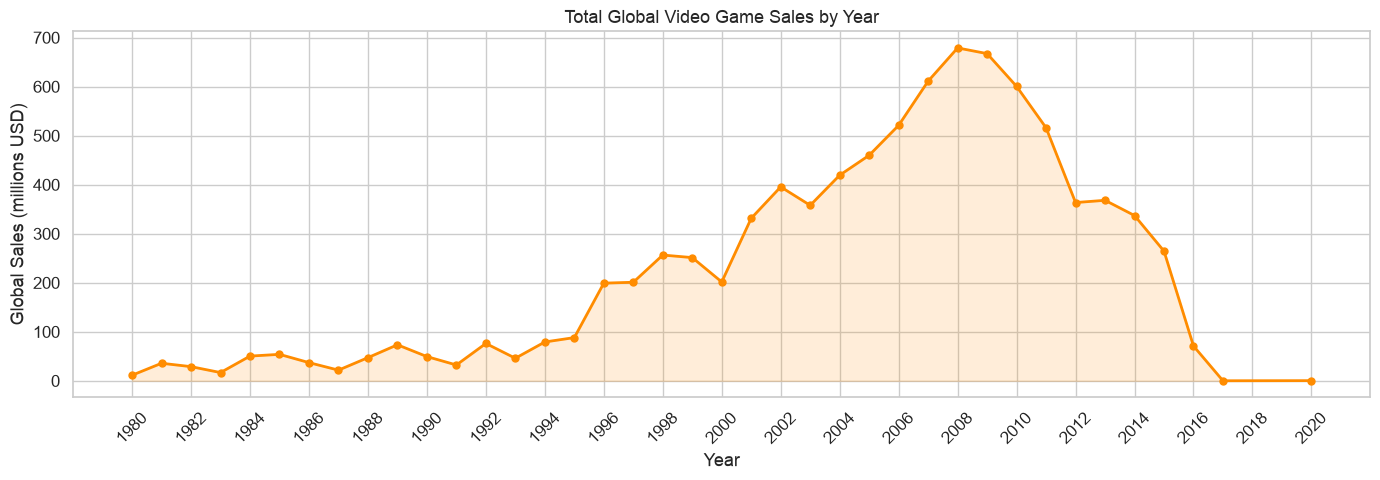


Peak year for sales: 2008 — $678.90M


In [23]:
# ── Global sales aggregated by year ──────────────────────────────
sales_per_year = df.groupby("Year")["Global_Sales"].sum().reset_index()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sales_per_year["Year"], sales_per_year["Global_Sales"],
        marker="o", linewidth=2, color="darkorange", markersize=5)
ax.fill_between(sales_per_year["Year"], sales_per_year["Global_Sales"],
                alpha=0.15, color="darkorange")
ax.set_title("Total Global Video Game Sales by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Global Sales (millions USD)")
ax.set_xticks(range(int(sales_per_year["Year"].min()), int(sales_per_year["Year"].max()) + 1, 2))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

peak_sales_year = sales_per_year.loc[sales_per_year["Global_Sales"].idxmax()]
print(f"\nPeak year for sales: {int(peak_sales_year['Year'])} — ${peak_sales_year['Global_Sales']:,.2f}M")

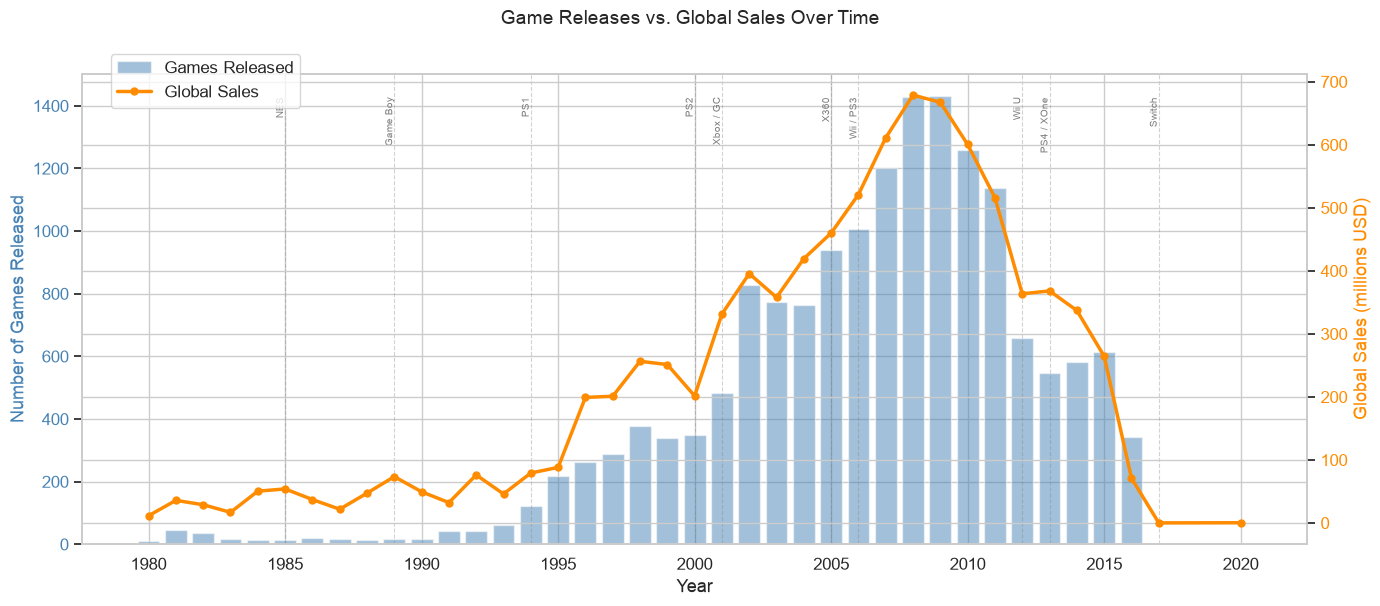

In [24]:
# ── Releases vs. Sales — dual-axis chart ─────────────────────────
fig, ax1 = plt.subplots(figsize=(14, 6))

color1, color2 = "steelblue", "darkorange"

ax1.bar(games_per_year["Year"], games_per_year["Game_Count"],
        color=color1, alpha=0.5, label="Games Released", width=0.8)
ax1.set_xlabel("Year")
ax1.set_ylabel("Number of Games Released", color=color1)
ax1.tick_params(axis="y", labelcolor=color1)

ax2 = ax1.twinx()
ax2.plot(sales_per_year["Year"], sales_per_year["Global_Sales"],
         color=color2, marker="o", linewidth=2.5, markersize=5, label="Global Sales")
ax2.set_ylabel("Global Sales (millions USD)", color=color2)
ax2.tick_params(axis="y", labelcolor=color2)

# Console launch annotations
events = {
    1985: "NES",
    1989: "Game Boy",
    1994: "PS1",
    2000: "PS2",
    2001: "Xbox / GC",
    2005: "X360",
    2006: "Wii / PS3",
    2012: "Wii U",
    2013: "PS4 / XOne",
    2017: "Switch",
}
for yr, label in events.items():
    ax1.axvline(yr, color="gray", linestyle="--", alpha=0.35, linewidth=0.8)
    ax1.text(yr, ax1.get_ylim()[1] * 0.95, label,
             rotation=90, fontsize=7, va="top", ha="right", color="gray")

fig.suptitle("Game Releases vs. Global Sales Over Time", fontsize=14, y=1.01)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.95))
plt.tight_layout()
plt.show()

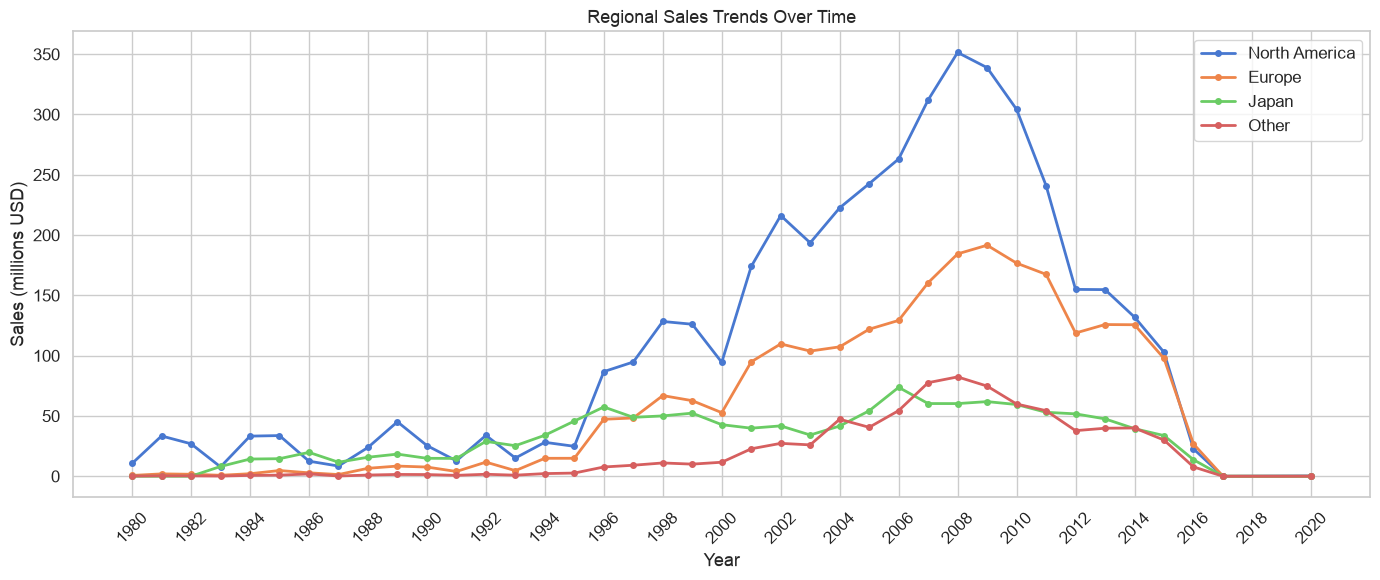

In [25]:
# ── Regional sales trends over time ──────────────────────────────
region_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
region_labels = ["North America", "Europe", "Japan", "Other"]

regional_yearly = df.groupby("Year")[region_cols].sum().reset_index()

fig, ax = plt.subplots(figsize=(14, 6))
for col, label in zip(region_cols, region_labels):
    ax.plot(regional_yearly["Year"], regional_yearly[col],
            marker="o", markersize=4, linewidth=2, label=label)

ax.set_title("Regional Sales Trends Over Time")
ax.set_xlabel("Year")
ax.set_ylabel("Sales (millions USD)")
ax.legend()
ax.set_xticks(range(int(regional_yearly["Year"].min()),
                    int(regional_yearly["Year"].max()) + 1, 2))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
# ── Trend assessment: growth phases ──────────────────────────────
# Split the timeline into meaningful eras
eras = [
    ("Early Era (1980-1995)",  1980, 1995),
    ("Growth Era (1996-2005)", 1996, 2005),
    ("Peak Era (2006-2011)",   2006, 2011),
    ("Decline Era (2012-2020)", 2012, 2020),
]

print("Sales by Industry Era")
print("=" * 65)
for name, start, end in eras:
    era_data = df[(df["Year"] >= start) & (df["Year"] <= end)]
    total = era_data["Global_Sales"].sum()
    count = len(era_data)
    avg = era_data["Global_Sales"].mean()
    print(f"{name:30s}  |  {count:5,} games  |  ${total:8,.1f}M total  |  ${avg:.2f}M avg")

# Year-over-year growth rate
sales_per_year["YoY_Growth_%"] = sales_per_year["Global_Sales"].pct_change() * 100
print(f"\nAverage YoY growth (all years): {sales_per_year['YoY_Growth_%'].mean():+.1f}%")
print(f"Peak-to-latest decline: "
      f"${peak_sales_year['Global_Sales']:,.1f}M ({int(peak_sales_year['Year'])}) → "
      f"${sales_per_year.iloc[-1]['Global_Sales']:,.1f}M ({int(sales_per_year.iloc[-1]['Year'])})")

Sales by Industry Era
Early Era (1980-1995)           |    705 games  |  $   747.6M total  |  $1.06M avg
Growth Era (1996-2005)          |  5,408 games  |  $ 3,073.5M total  |  $0.57M avg
Peak Era (2006-2011)            |  7,467 games  |  $ 3,594.8M total  |  $0.48M avg
Decline Era (2012-2020)         |  2,747 games  |  $ 1,404.4M total  |  $0.51M avg

Average YoY growth (all years): +28.2%
Peak-to-latest decline: $678.9M (2008) → $0.3M (2020)


#### Key Takeaways — Trends Over Time

| Observation | Detail |
|-------------|--------|
| **Rise (1996 – 2008)** | The industry experienced explosive growth driven by the PS1/PS2/Xbox generation and the casual-gaming Wii/DS boom. Both release counts and sales surged. |
| **Peak ≈ 2008 – 2009** | Global sales peaked around 2008–2009, coinciding with the Wii/DS phenomenon and blockbuster titles. |
| **Decline (2010+)** | A steady decline follows as the dataset captures fewer mobile/digital titles. The dataset primarily covers physical retail sales, so the apparent "decline" partly reflects the industry's shift to digital distribution rather than an actual contraction. |
| **Console launches matter** | Clear sales bumps align with major console launches (PS2 in 2000, Wii/PS3 in 2006, PS4/XOne in 2013). |
| **Regional convergence** | NA dominated early, but EU grew significantly from 2000 onwards. Japan remained relatively stable throughout. |

---
### 2.3 Genre Analysis

Which genres are the most common, and which generate the most revenue?

In [27]:
# ── Games per genre & sales per genre ────────────────────────────
genre_stats = (
    df.groupby("Genre")
      .agg(
          Game_Count=("Name", "size"),
          Total_Sales=("Global_Sales", "sum"),
          Avg_Sales=("Global_Sales", "mean"),
          Median_Sales=("Global_Sales", "median"),
          Max_Sales=("Global_Sales", "max"),
      )
      .sort_values("Total_Sales", ascending=False)
      .reset_index()
)

genre_stats["Share_%"] = (genre_stats["Total_Sales"] / genre_stats["Total_Sales"].sum() * 100).round(1)

print("Genre Summary (sorted by total global sales):\n")
genre_stats

Genre Summary (sorted by total global sales):



,Genre,Game_Count,Total_Sales,Avg_Sales,Median_Sales,Max_Sales,Share_%
0,Action,3253,1722.88,0.53,0.19,21.40,19.50
1,Sports,2304,1309.24,0.57,0.22,82.74,14.80
2,Shooter,1282,1026.20,0.80,0.23,28.31,11.60
3,Role-Playing,1471,923.84,0.63,0.19,31.37,10.50
4,Platform,876,829.15,0.95,0.28,40.24,9.40
5,Misc,1710,797.62,0.47,0.16,29.02,9.00
6,Racing,1226,726.77,0.59,0.19,35.82,8.20
7,Fighting,836,444.05,0.53,0.21,13.04,5.00
8,Simulation,851,390.16,0.46,0.16,24.76,4.40
9,Puzzle,571,242.22,0.42,0.10,30.26,2.70


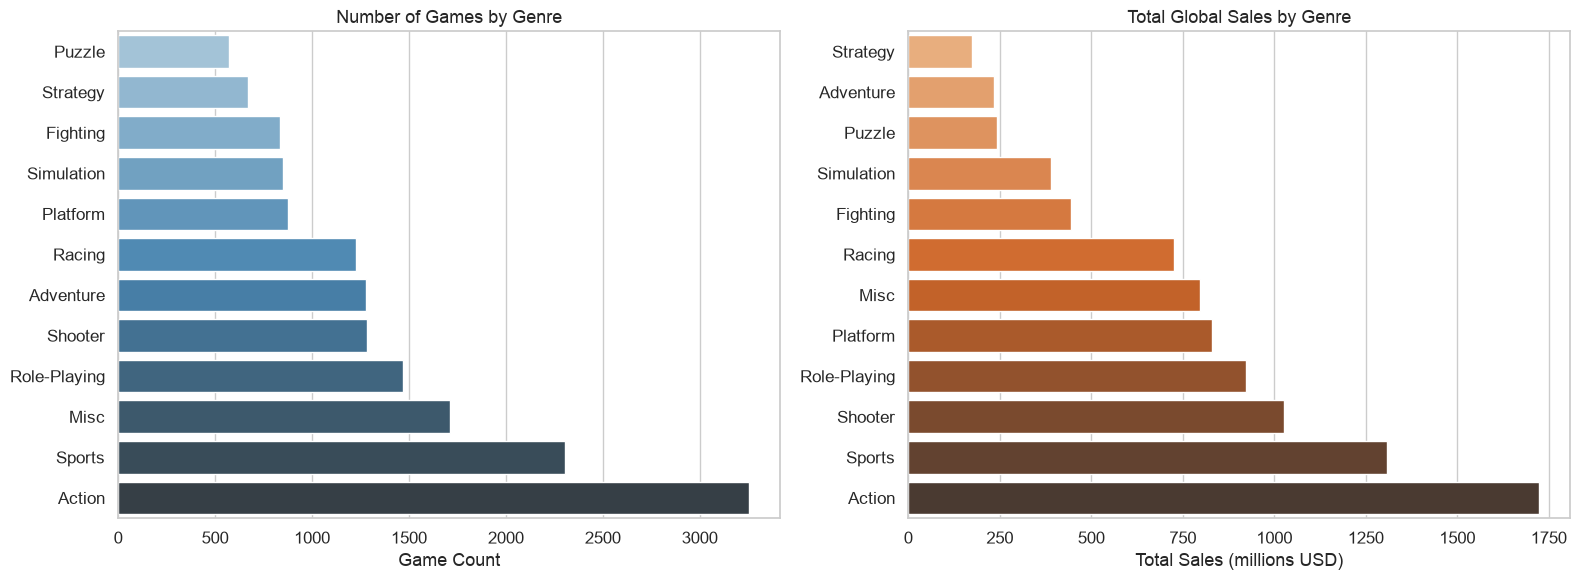

In [28]:
# ── Side-by-side: Game Count vs Total Sales by Genre ─────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left — Game count
order_count = genre_stats.sort_values("Game_Count", ascending=True)["Genre"]
sns.barplot(data=genre_stats, y="Genre", x="Game_Count",
            order=order_count, palette="Blues_d", ax=axes[0])
axes[0].set_title("Number of Games by Genre")
axes[0].set_xlabel("Game Count")
axes[0].set_ylabel("")

# Right — Total sales
order_sales = genre_stats.sort_values("Total_Sales", ascending=True)["Genre"]
sns.barplot(data=genre_stats, y="Genre", x="Total_Sales",
            order=order_sales, palette="Oranges_d", ax=axes[1])
axes[1].set_title("Total Global Sales by Genre")
axes[1].set_xlabel("Total Sales (millions USD)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

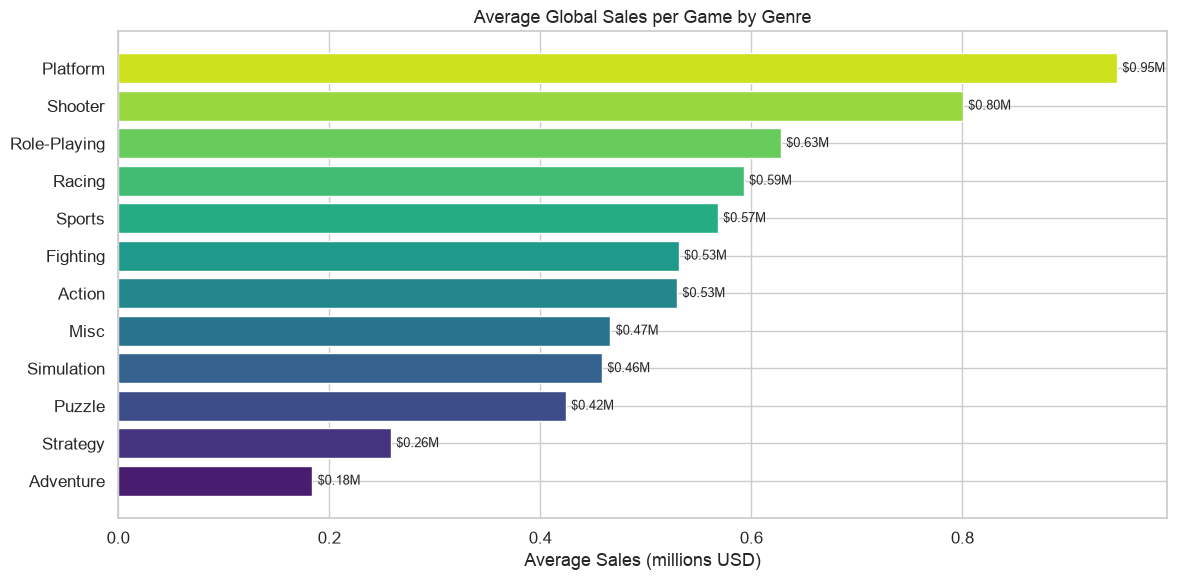

In [29]:
# ── Average sales per game by genre ──────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

genre_sorted = genre_stats.sort_values("Avg_Sales", ascending=True)
colors = sns.color_palette("viridis", n_colors=len(genre_sorted))

bars = ax.barh(genre_sorted["Genre"], genre_sorted["Avg_Sales"], color=colors)
ax.set_title("Average Global Sales per Game by Genre")
ax.set_xlabel("Average Sales (millions USD)")
ax.set_ylabel("")

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.005, bar.get_y() + bar.get_height() / 2,
            f"${width:.2f}M", va="center", fontsize=9)

plt.tight_layout()
plt.show()

In [30]:
# ── Popularity rank vs Revenue rank ──────────────────────────────
rank_compare = genre_stats[["Genre", "Game_Count", "Total_Sales"]].copy()
rank_compare["Count_Rank"] = rank_compare["Game_Count"].rank(ascending=False).astype(int)
rank_compare["Sales_Rank"] = rank_compare["Total_Sales"].rank(ascending=False).astype(int)
rank_compare["Rank_Diff"] = rank_compare["Count_Rank"] - rank_compare["Sales_Rank"]
rank_compare = rank_compare.sort_values("Sales_Rank")

print("Genre Rank Comparison — Count vs Sales")
print("(Positive Rank_Diff = genre earns more revenue than its release volume suggests)\n")
rank_compare

Genre Rank Comparison — Count vs Sales
(Positive Rank_Diff = genre earns more revenue than its release volume suggests)



,Genre,Game_Count,Total_Sales,Count_Rank,Sales_Rank,Rank_Diff
0,Action,3253,1722.88,1,1,0
1,Sports,2304,1309.24,2,2,0
2,Shooter,1282,1026.20,5,3,2
3,Role-Playing,1471,923.84,4,4,0
4,Platform,876,829.15,8,5,3
5,Misc,1710,797.62,3,6,-3
6,Racing,1226,726.77,7,7,0
7,Fighting,836,444.05,10,8,2
8,Simulation,851,390.16,9,9,0
9,Puzzle,571,242.22,12,10,2


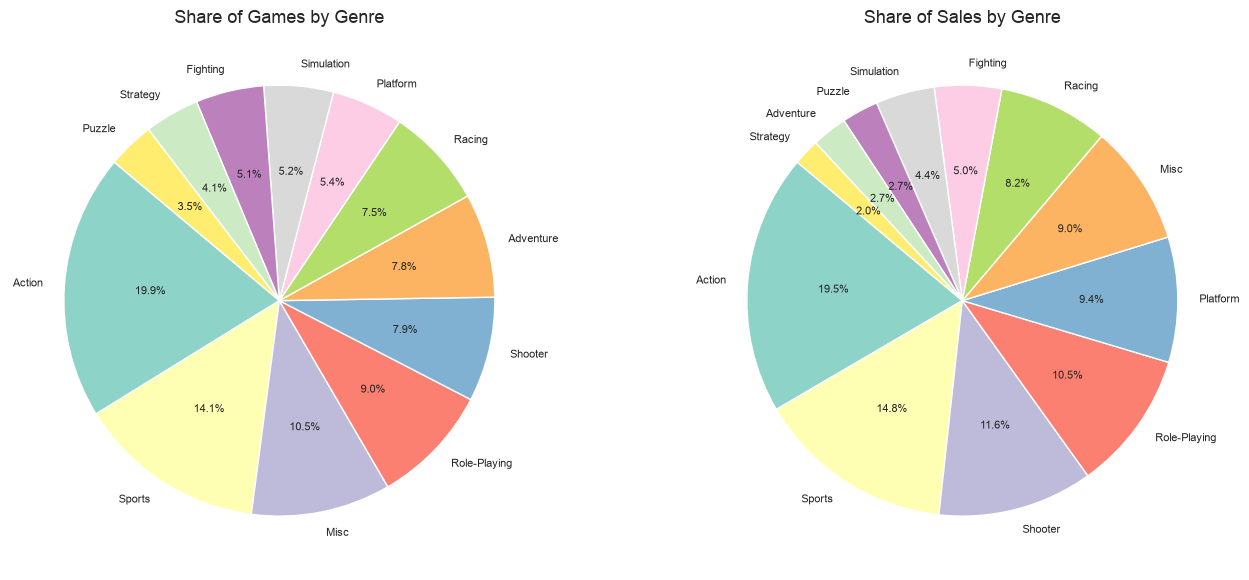

In [31]:
# ── Genre share: stacked view ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie — by game count
axes[0].pie(
    genre_stats.sort_values("Game_Count", ascending=False)["Game_Count"],
    labels=genre_stats.sort_values("Game_Count", ascending=False)["Genre"],
    autopct="%1.1f%%", startangle=140, textprops={"fontsize": 8},
    colors=sns.color_palette("Set3", len(genre_stats))
)
axes[0].set_title("Share of Games by Genre")

# Pie — by total sales
axes[1].pie(
    genre_stats.sort_values("Total_Sales", ascending=False)["Total_Sales"],
    labels=genre_stats.sort_values("Total_Sales", ascending=False)["Genre"],
    autopct="%1.1f%%", startangle=140, textprops={"fontsize": 8},
    colors=sns.color_palette("Set3", len(genre_stats))
)
axes[1].set_title("Share of Sales by Genre")

plt.tight_layout()
plt.show()

#### Key Takeaways — Genre Analysis

| Insight | Detail |
|---------|--------|
| **Action dominates** | Action is both the most released and highest-grossing genre by total sales. |
| **Sports punches above its weight** | Sports has fewer releases than Action but very high total sales, thanks to mega-hits like *Wii Sports* and annual franchises (FIFA, Madden). |
| **Platform & Shooter are high-value** | These genres have some of the highest *average* sales per game, indicating strong commercial performance per title. |
| **Puzzle & Adventure lag** | Despite reasonable release counts, these genres generate lower total and average sales. |
| **Strategy is niche** | Lowest game count and lowest total sales — strategy games are underrepresented on consoles (they thrive more on PC, which is underrepresented in this dataset). |

---
### 2.4 Platform Analysis

What are the most popular platforms by number of games and total sales, and how has platform popularity changed over time?

In [32]:
# ── Platform rankings: games released & total sales ────────────
platform_stats = (
    df.groupby("Platform")
      .agg(
          Game_Count=("Name", "size"),
          Total_Sales=("Global_Sales", "sum"),
          Avg_Sales=("Global_Sales", "mean"),
          Top_Game=("Global_Sales", "max"),
          First_Year=("Year", "min"),
          Last_Year=("Year", "max"),
      )
      .sort_values("Total_Sales", ascending=False)
      .reset_index()
)

platform_stats["Lifespan"] = (platform_stats["Last_Year"] - platform_stats["First_Year"]).astype(int)
platform_stats["Share_%"] = (platform_stats["Total_Sales"] / platform_stats["Total_Sales"].sum() * 100).round(1)

print(f"Unique platforms: {df['Platform'].nunique()}\n")
platform_stats.head(15)

Unique platforms: 31



,Platform,Game_Count,Total_Sales,Avg_Sales,Top_Game,First_Year,Last_Year,Lifespan,Share_%
0,PS2,2127,1233.46,0.58,20.81,2000,2011,11,14.00
1,X360,1235,969.61,0.79,21.82,2005,2016,11,11.00
2,PS3,1304,949.35,0.73,21.40,2006,2016,10,10.80
3,Wii,1290,909.81,0.71,82.74,2006,2015,9,10.30
4,DS,2133,818.96,0.38,30.01,1985,2020,35,9.30
5,PS,1189,727.39,0.61,10.95,1994,2003,9,8.20
6,GBA,811,313.56,0.39,15.85,2000,2007,7,3.60
7,PSP,1197,291.71,0.24,7.72,2004,2015,11,3.30
8,PS4,336,278.10,0.83,14.24,2013,2017,4,3.20
9,PC,943,255.05,0.27,8.11,1985,2016,31,2.90


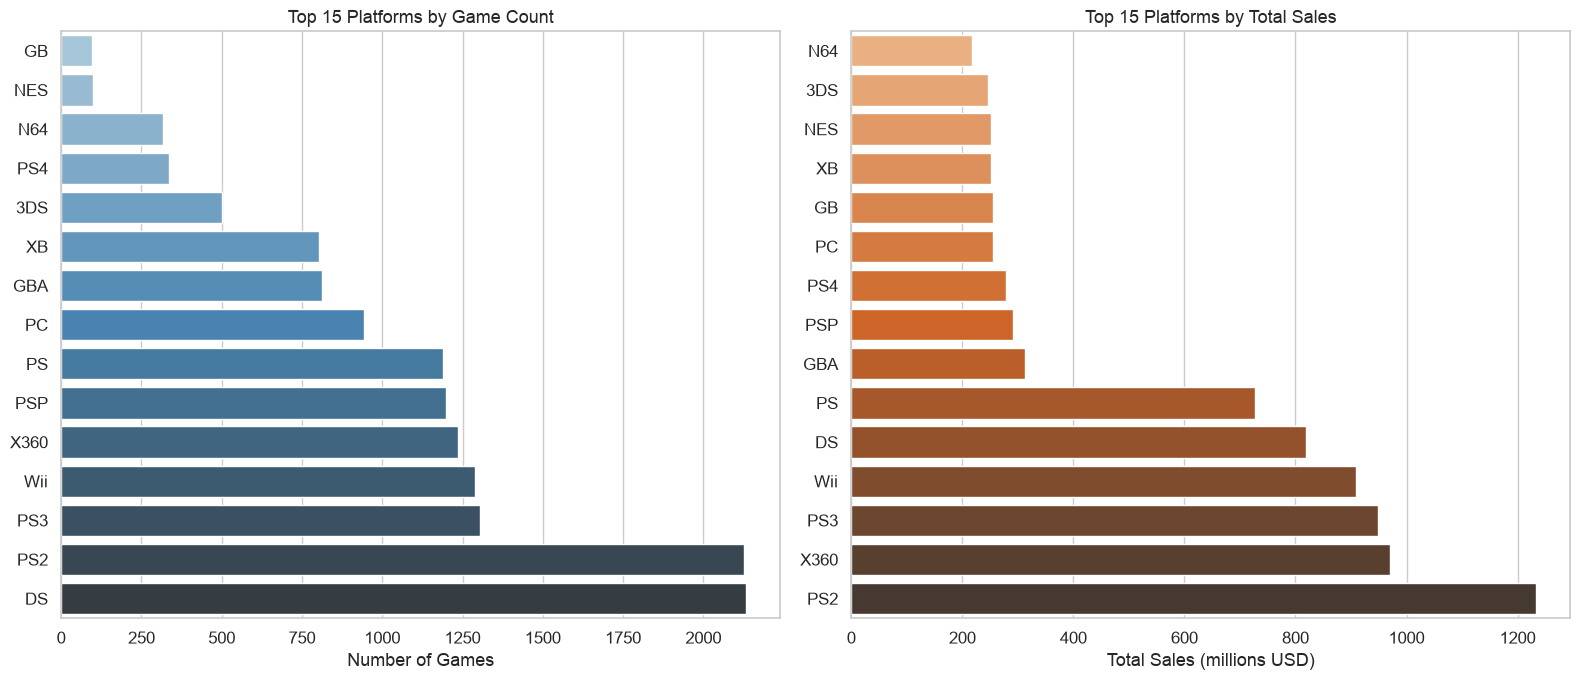

In [33]:
# ── Top 15 platforms: Game Count vs Total Sales ────────────────
top15 = platform_stats.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left — by game count
order_count = top15.sort_values("Game_Count", ascending=True)["Platform"]
sns.barplot(data=top15, y="Platform", x="Game_Count",
            order=order_count, palette="Blues_d", ax=axes[0])
axes[0].set_title("Top 15 Platforms by Game Count")
axes[0].set_xlabel("Number of Games")
axes[0].set_ylabel("")

# Right — by total sales
order_sales = top15.sort_values("Total_Sales", ascending=True)["Platform"]
sns.barplot(data=top15, y="Platform", x="Total_Sales",
            order=order_sales, palette="Oranges_d", ax=axes[1])
axes[1].set_title("Top 15 Platforms by Total Sales")
axes[1].set_xlabel("Total Sales (millions USD)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

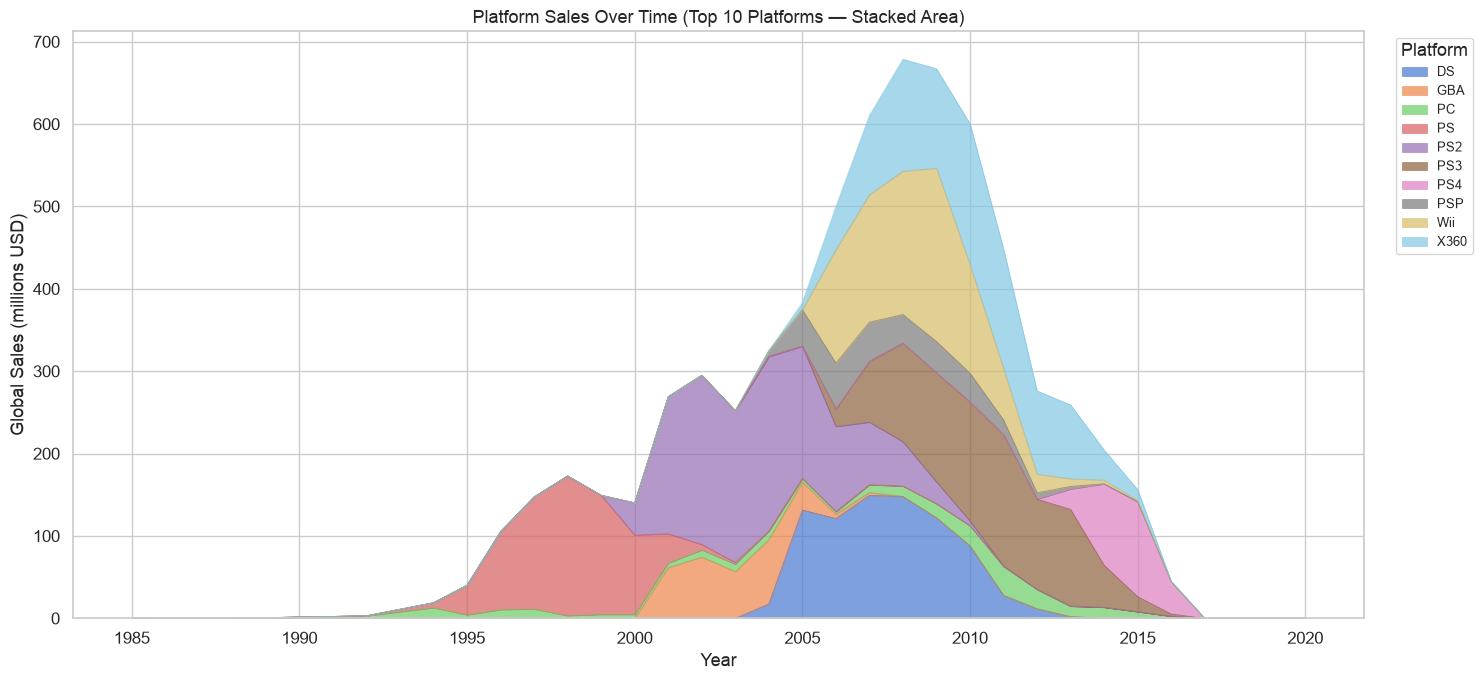

In [34]:
# ── Platform popularity over time — top 10 by sales ────────────
top10_platforms = platform_stats.head(10)["Platform"].tolist()

platform_yearly = (
    df[df["Platform"].isin(top10_platforms)]
      .groupby(["Year", "Platform"])["Global_Sales"]
      .sum()
      .unstack(fill_value=0)
)

fig, ax = plt.subplots(figsize=(15, 7))
platform_yearly.plot.area(ax=ax, alpha=0.7, linewidth=0.5)
ax.set_title("Platform Sales Over Time (Top 10 Platforms — Stacked Area)")
ax.set_xlabel("Year")
ax.set_ylabel("Global Sales (millions USD)")
ax.legend(title="Platform", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

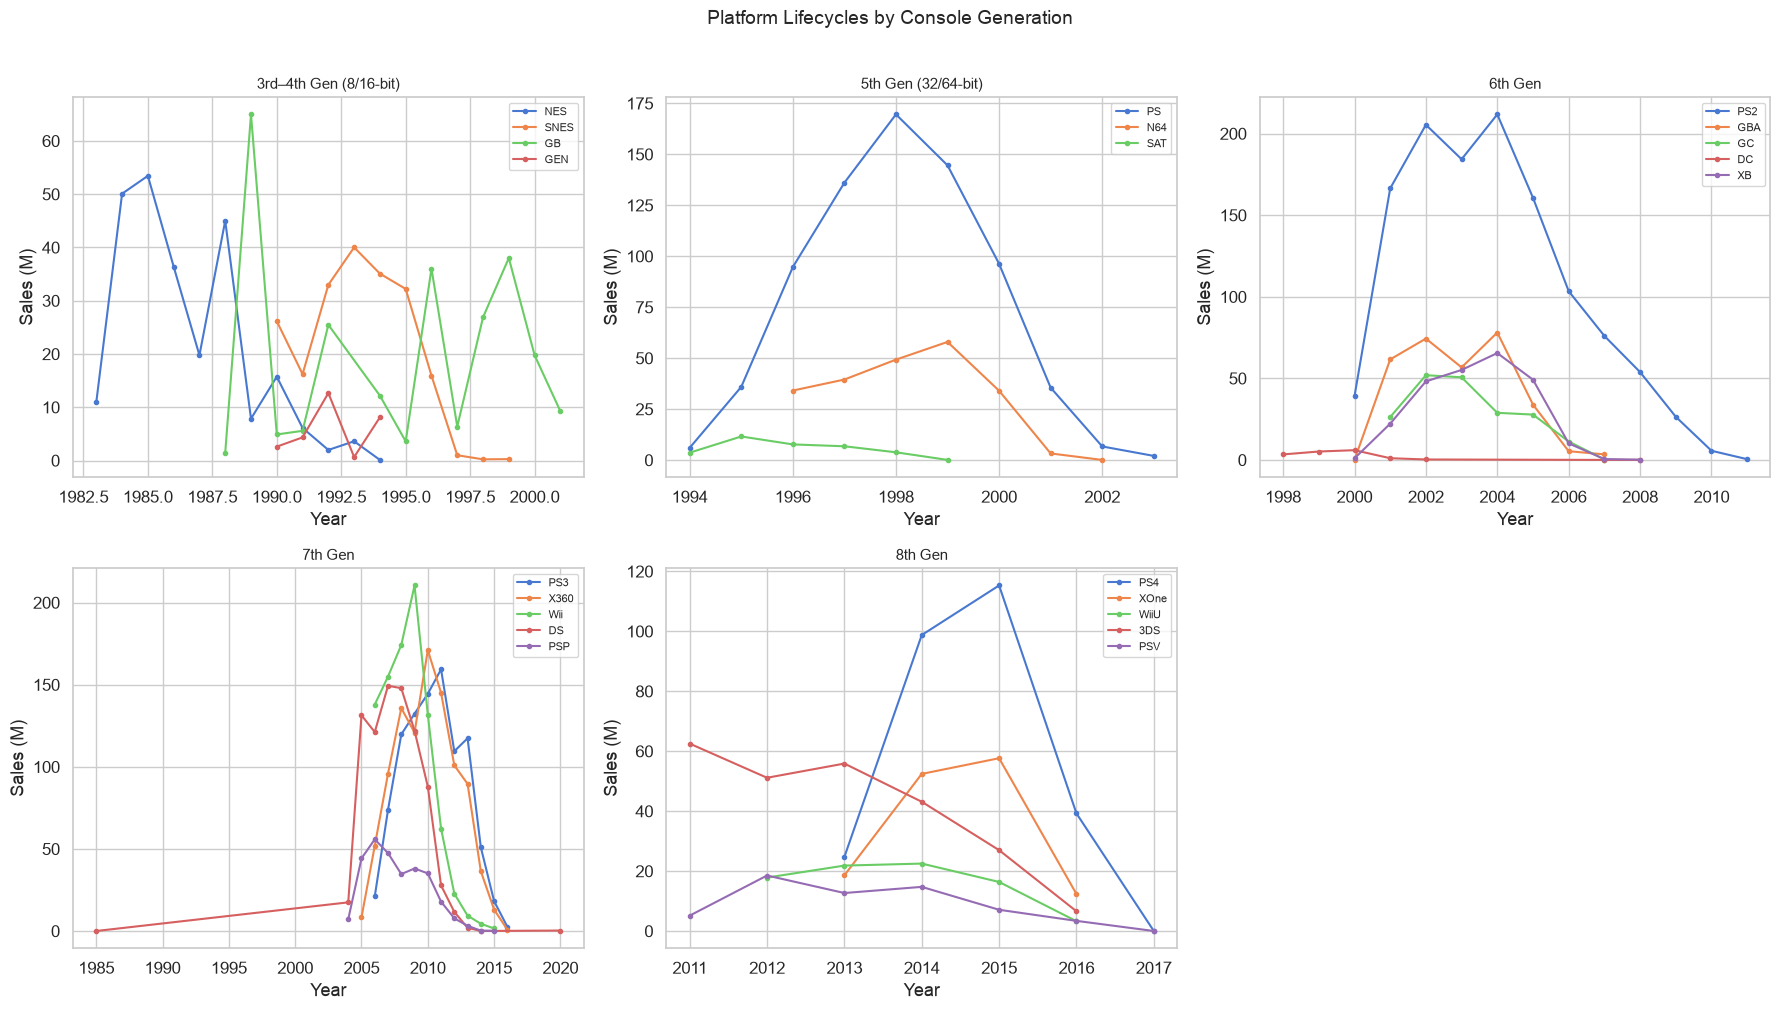

In [35]:
# ── Platform lifecycles — individual trend lines ───────────────
# Group into console generations for cleaner visualization
generations = {
    "3rd–4th Gen (8/16-bit)": ["NES", "SNES", "GB", "GEN"],
    "5th Gen (32/64-bit)":    ["PS", "N64", "SAT"],
    "6th Gen":                ["PS2", "GBA", "GC", "DC", "XB"],
    "7th Gen":                ["PS3", "X360", "Wii", "DS", "PSP"],
    "8th Gen":                ["PS4", "XOne", "WiiU", "3DS", "PSV"],
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey=False)
axes = axes.flatten()

for idx, (gen_name, platforms) in enumerate(generations.items()):
    ax = axes[idx]
    for plat in platforms:
        plat_data = df[df["Platform"] == plat].groupby("Year")["Global_Sales"].sum()
        if not plat_data.empty:
            ax.plot(plat_data.index, plat_data.values, marker="o",
                    markersize=3, linewidth=1.5, label=plat)
    ax.set_title(gen_name, fontsize=11)
    ax.set_xlabel("Year")
    ax.set_ylabel("Sales (M)")
    ax.legend(fontsize=8)

# Hide the unused subplot
axes[-1].set_visible(False)

fig.suptitle("Platform Lifecycles by Console Generation", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [36]:
# ── Console generation summary ────────────────────────────────
print("Console Generation Summary")
print("=" * 75)

for gen_name, platforms in generations.items():
    gen_data = df[df["Platform"].isin(platforms)]
    total = gen_data["Global_Sales"].sum()
    count = len(gen_data)
    top_plat = gen_data.groupby("Platform")["Global_Sales"].sum().idxmax()
    top_plat_sales = gen_data.groupby("Platform")["Global_Sales"].sum().max()
    print(f"{gen_name:30s} | {count:5,} games | ${total:8,.1f}M | "
          f"Leader: {top_plat} (${top_plat_sales:,.1f}M)")

Console Generation Summary
3rd–4th Gen (8/16-bit)         |   461 games | $   733.9M | Leader: GB ($254.4M)
5th Gen (32/64-bit)            | 1,678 games | $   979.2M | Leader: PS ($727.4M)
6th Gen                        | 4,335 games | $ 2,012.2M | Leader: PS2 ($1,233.5M)
7th Gen                        | 7,159 games | $ 3,939.4M | Leader: X360 ($969.6M)
8th Gen                        | 1,604 games | $   808.9M | Leader: PS4 ($278.1M)


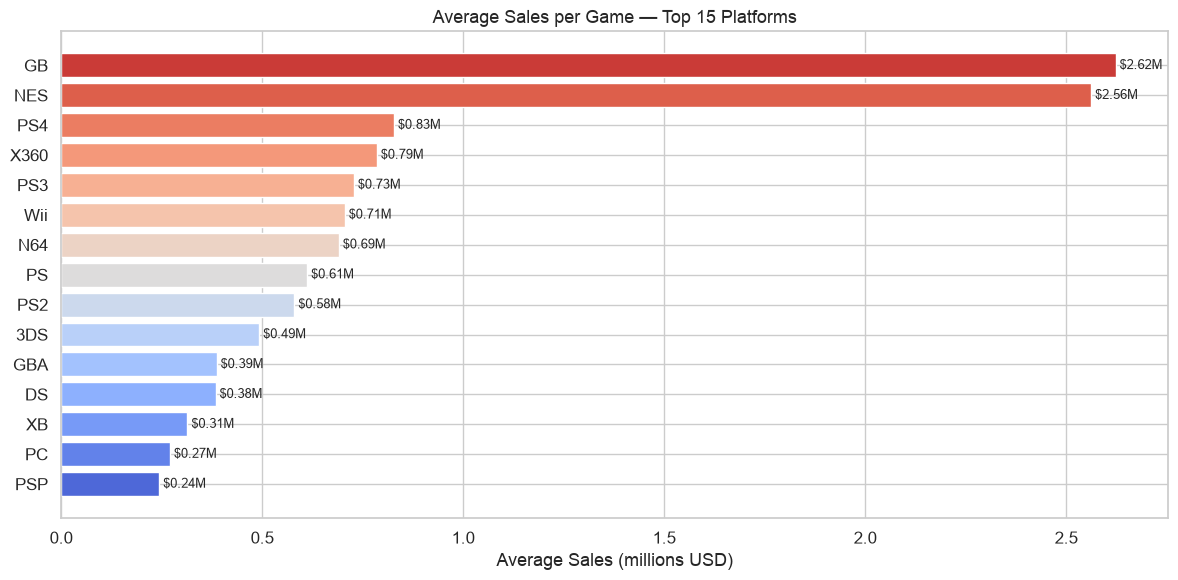

In [37]:
# ── Average sales per game — top 15 platforms ─────────────────
top15_avg = platform_stats.head(15).sort_values("Avg_Sales", ascending=True)

fig, ax = plt.subplots(figsize=(12, 6))
colors = sns.color_palette("coolwarm", n_colors=len(top15_avg))
bars = ax.barh(top15_avg["Platform"], top15_avg["Avg_Sales"], color=colors)
ax.set_title("Average Sales per Game — Top 15 Platforms")
ax.set_xlabel("Average Sales (millions USD)")
ax.set_ylabel("")

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.01, bar.get_y() + bar.get_height() / 2,
            f"${width:.2f}M", va="center", fontsize=9)

plt.tight_layout()
plt.show()

#### Key Takeaways — Platform Analysis

| Insight | Detail |
|---------|--------|
| **PS2 is king** | The PlayStation 2 leads in both total sales and game count — the best-selling console of all time with the largest library. |
| **Wii & DS — casual revolution** | Despite shorter lifespans, the Wii and DS generated enormous sales thanks to casual/family gaming appeal. Wii has the highest average sales per game among top platforms. |
| **Clear generational cycles** | Each console generation follows a bell-curve lifecycle: rapid growth → 3–5 year peak → gradual decline as the next generation launches. |
| **Handheld vs. home** | Handhelds (DS, GB, GBA, 3DS, PSP) collectively represent a huge share — portable gaming has always been a major market segment. |
| **7th Gen was the peak** | The PS3/X360/Wii/DS generation (2005–2012) produced the most total sales of any generation in this dataset. |
| **Platform fragmentation** | Later generations show more competitors splitting the market, with no single platform dominating as strongly as PS2 did in Gen 6. |

---
### 2.5 Regional Analysis

Compare preferences between North America, Europe, and Japan. Are there genres that dominate in one region but not others?

In [38]:
# ── Regional sales comparison ─────────────────────────────────────
region_map = {
    "NA_Sales": "North America",
    "EU_Sales": "Europe",
    "JP_Sales": "Japan",
    "Other_Sales": "Other",
}
region_cols = list(region_map.keys())
region_labels = list(region_map.values())

totals = df[region_cols].sum()
means = df[region_cols].mean()
medians = df[region_cols].median()

region_overview = pd.DataFrame({
    "Region": region_labels,
    "Total Sales (M)": totals.values.round(2),
    "Mean (M)": means.values.round(3),
    "Median (M)": medians.values.round(3),
    "Share (%)": (totals.values / totals.values.sum() * 100).round(1),
}).reset_index(drop=True)

print("Regional Sales Overview:\n")
region_overview

Regional Sales Overview:



,Region,Total Sales (M),Mean (M),Median (M),Share (%)
0,North America,4333.43,0.27,0.08,49.20
1,Europe,2409.12,0.15,0.02,27.30
2,Japan,1284.30,0.08,0.00,14.60
3,Other,789.01,0.05,0.01,8.90


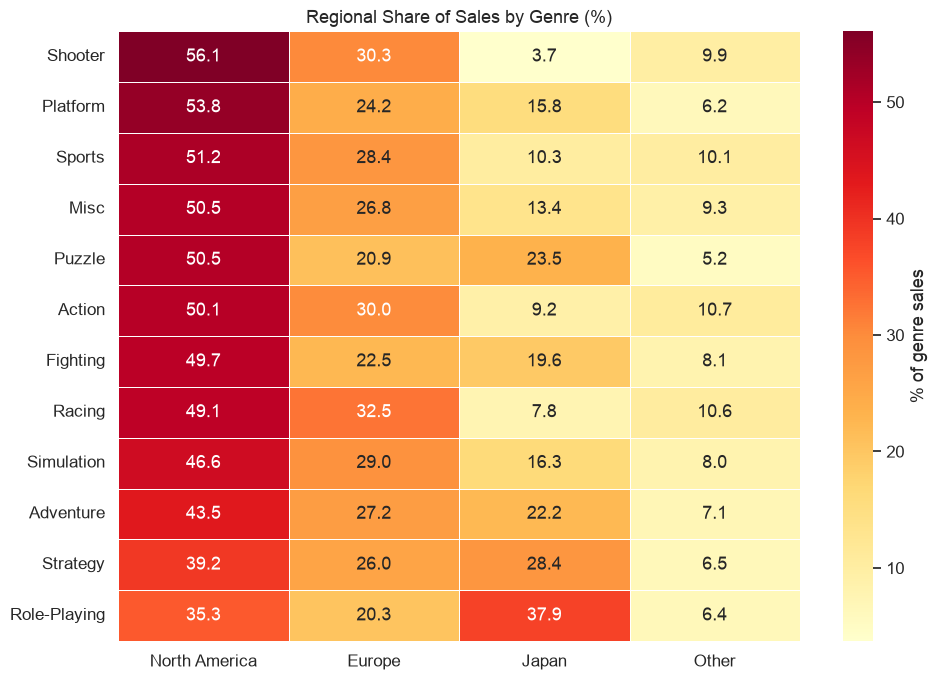

In [39]:
# ── Regional sales proportions per genre ─────────────────────────
genre_region = df.groupby("Genre")[region_cols].sum()
genre_region_pct = genre_region.div(genre_region.sum(axis=1), axis=0) * 100
genre_region_pct.columns = region_labels

# Sort genres by NA share for readable ordering
genre_region_pct = genre_region_pct.sort_values("North America", ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(genre_region_pct, annot=True, fmt=".1f", cmap="YlOrRd",
            linewidths=0.5, ax=ax, cbar_kws={"label": "% of genre sales"})
ax.set_title("Regional Share of Sales by Genre (%)")
ax.set_ylabel("")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

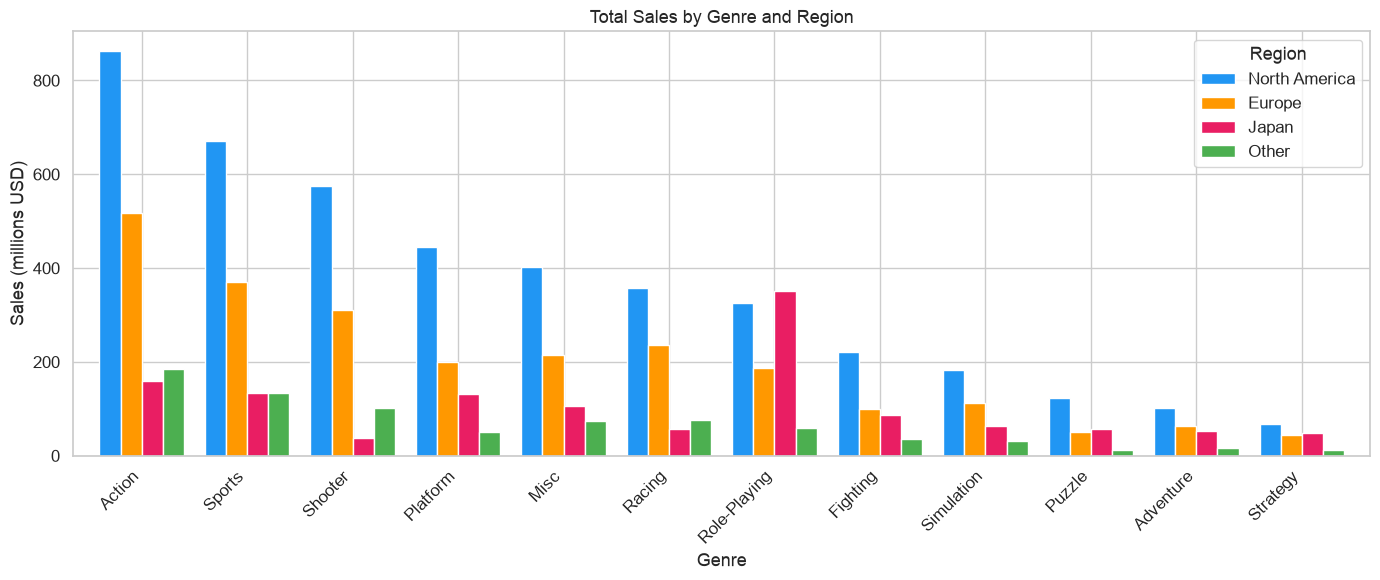

In [40]:
# ── Genre sales per region — grouped bar chart ────────────────────
genre_region_abs = genre_region.copy()
genre_region_abs.columns = region_labels
genre_region_abs = genre_region_abs.sort_values("North America", ascending=False)

genre_region_abs.plot(
    kind="bar", figsize=(14, 6), width=0.8,
    color=["#2196F3", "#FF9800", "#E91E63", "#4CAF50"]
)
plt.title("Total Sales by Genre and Region")
plt.xlabel("Genre")
plt.ylabel("Sales (millions USD)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Region")
plt.tight_layout()
plt.show()

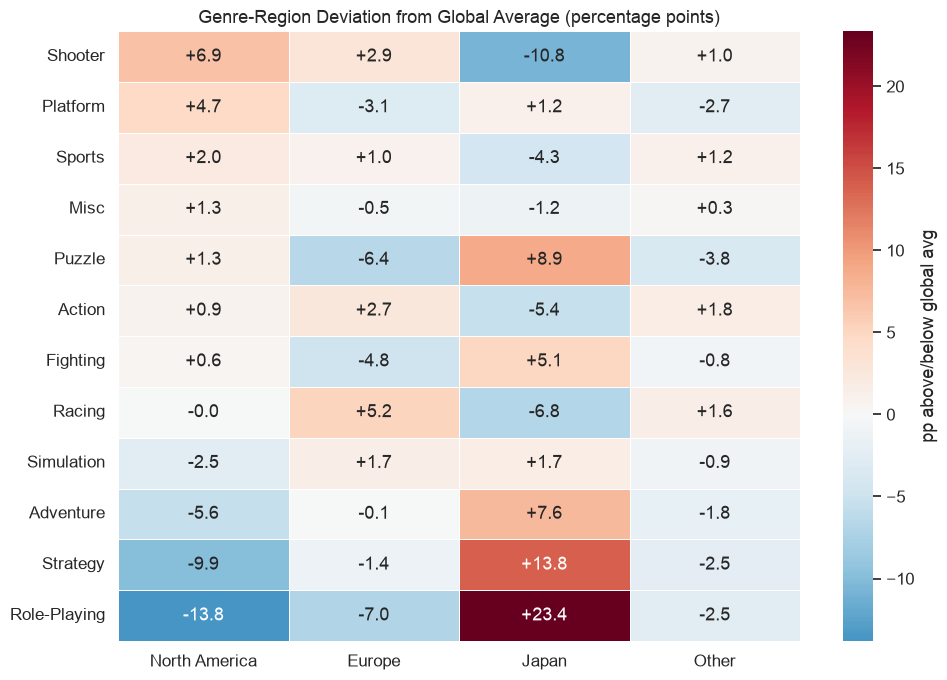


Strongest Regional Over-Indexing (genre dominates in that region):

  North America        → Shooter          (+6.9 pp above average)
  Europe               → Racing           (+5.2 pp above average)
  Japan                → Role-Playing     (+23.4 pp above average)
  Other                → Action           (+1.8 pp above average)

Strongest Regional Under-Indexing (genre weak in that region):

  North America        → Role-Playing     (-13.8 pp below average)
  Europe               → Role-Playing     (-7.0 pp below average)
  Japan                → Shooter          (-10.8 pp below average)
  Other                → Puzzle           (-3.8 pp below average)


In [41]:
# ── Regional genre dominance — identify outliers ──────────────────
# Calculate each region's share across genres, then compare to the
# overall regional average to find over-/under-indexed combinations.

overall_share = totals / totals.sum() * 100  # global avg share per region

# Deviation from the global average (positive = over-indexed)
deviation = genre_region_pct.copy()
for col, avg in zip(region_labels, overall_share.values):
    deviation[col] = deviation[col] - avg

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(deviation, annot=True, fmt="+.1f", cmap="RdBu_r", center=0,
            linewidths=0.5, ax=ax,
            cbar_kws={"label": "pp above/below global avg"})
ax.set_title("Genre-Region Deviation from Global Average (percentage points)")
ax.set_ylabel("")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

# Highlight the strongest deviations
print("\nStrongest Regional Over-Indexing (genre dominates in that region):\n")
for region in region_labels:
    top_genre = deviation[region].idxmax()
    val = deviation[region].max()
    print(f"  {region:20s} → {top_genre:15s}  ({val:+.1f} pp above average)")

print("\nStrongest Regional Under-Indexing (genre weak in that region):\n")
for region in region_labels:
    bot_genre = deviation[region].idxmin()
    val = deviation[region].min()
    print(f"  {region:20s} → {bot_genre:15s}  ({val:+.1f} pp below average)")

In [42]:
# ── Top 5 games in each region ────────────────────────────────────
print("Top 5 Best-Selling Games by Region\n")
print("=" * 70)

for col, label in region_map.items():
    top5 = df.nlargest(5, col)[["Name", "Platform", "Genre", col]]
    print(f"\n{label}:")
    for rank, (_, row) in enumerate(top5.iterrows(), 1):
        print(f"  {rank}. {row['Name']:40s} ({row['Platform']:4s})  "
              f"{row['Genre']:15s}  ${row[col]:.2f}M")

Top 5 Best-Selling Games by Region


North America:
  1. Wii Sports                               (Wii )  Sports           $41.49M
  2. Super Mario Bros.                        (NES )  Platform         $29.08M
  3. Duck Hunt                                (NES )  Shooter          $26.93M
  4. Tetris                                   (GB  )  Puzzle           $23.20M
  5. Mario Kart Wii                           (Wii )  Racing           $15.85M

Europe:
  1. Wii Sports                               (Wii )  Sports           $29.02M
  2. Mario Kart Wii                           (Wii )  Racing           $12.88M
  3. Wii Sports Resort                        (Wii )  Sports           $11.01M
  4. Nintendogs                               (DS  )  Simulation       $11.00M
  5. Grand Theft Auto V                       (PS3 )  Action           $9.27M

Japan:
  1. Pokemon Red/Pokemon Blue                 (GB  )  Role-Playing     $10.22M
  2. Pokemon Gold/Pokemon Silver              (GB  )  Role-Play

#### Key Takeaways — Regional Analysis

| Insight | Detail |
|---------|--------|
| **NA dominates overall** | North America accounts for ~49% of all sales and leads in almost every genre. |
| **Japan loves Role-Playing** | Role-Playing games are heavily over-indexed in Japan (+25 pp above the global average). The JP market has a distinctly different taste profile from NA/EU. |
| **Shooter is a Western genre** | Shooters are strongly over-indexed in NA and EU but significantly under-indexed in Japan. |
| **Europe mirrors NA (mostly)** | EU's genre preferences are similar to NA but at lower volumes. EU slightly over-indexes in Racing and Sports (FIFA effect). |
| **Cultural preferences are real** | The deviation heatmap clearly shows that genre popularity is not uniform — each region has distinct tastes, especially Japan vs. the West. |

---
### 2.6 Publisher Insights

Identify the top publishers by total global sales, analyze their genre portfolios, and discover hit publishers that dominate specific genres.

In [43]:
# ── Identify top publishers by total global sales ──────────────────
publisher_stats = (
    df.groupby("Publisher")
      .agg(
          Game_Count=("Name", "size"),
          Total_Sales=("Global_Sales", "sum"),
          Avg_Sales=("Global_Sales", "mean"),
          Top_Game=("Name", lambda s: df.loc[s.index, "Name"].iloc[df.loc[s.index, "Global_Sales"].argmax()]),
          Top_Game_Sales=("Global_Sales", "max"),
      )
      .sort_values("Total_Sales", ascending=False)
      .reset_index()
)

publisher_stats["Share_%"] = (publisher_stats["Total_Sales"] / df["Global_Sales"].sum() * 100).round(2)
top10_publishers = publisher_stats.head(10).copy()
top10_publishers.index = range(1, 11)
top10_publishers.index.name = "#"

print("Top 10 Publishers by Global Sales:\n")
top10_publishers[["Publisher", "Game_Count", "Total_Sales", "Avg_Sales", "Top_Game", "Top_Game_Sales", "Share_%"]]

Top 10 Publishers by Global Sales:



,Publisher,Game_Count,Total_Sales,Avg_Sales,Top_Game,Top_Game_Sales,Share_%
#,,,,,,,
1,Nintendo,696,1784.43,2.56,Wii Sports,82.74,20.23
2,Electronic Arts,1339,1093.39,0.82,FIFA 16,8.49,12.40
3,Activision,966,721.41,0.75,Call of Duty: Modern Warfare 3,14.76,8.18
4,Sony Computer Entertainment,682,607.28,0.89,Gran Turismo 3: A-Spec,14.98,6.88
5,Ubisoft,918,473.54,0.52,Just Dance 3,10.26,5.37
6,Take-Two Interactive,412,399.30,0.97,Grand Theft Auto V,21.40,4.53
7,THQ,712,340.44,0.48,WWF SmackDown!,3.58,3.86
8,Konami Digital Entertainment,823,278.56,0.34,Metal Gear Solid 2: Sons of Liberty,6.05,3.16
9,Sega,632,270.70,0.43,Mario & Sonic at the Olympic Games,8.06,3.07


findfont: Failed to find font weight semibold for Arial, now using 700.


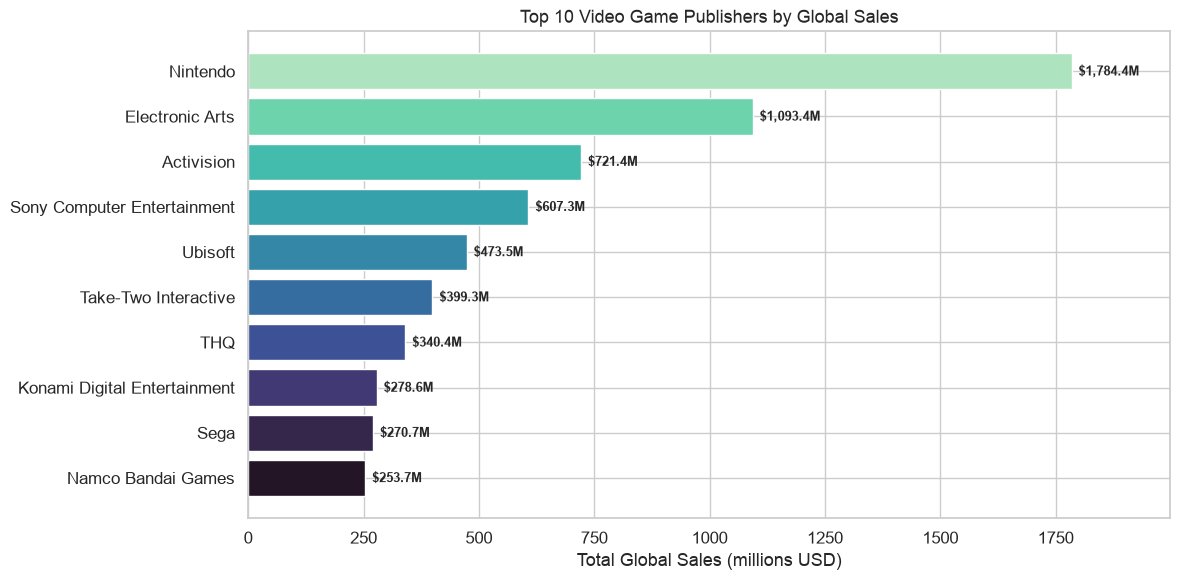

In [44]:
# ── Visualize top 10 publisher rankings ───────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

sorted_top10 = top10_publishers.sort_values("Total_Sales", ascending=True)
colors = sns.color_palette("mako", n_colors=10)
bars = ax.barh(sorted_top10["Publisher"], sorted_top10["Total_Sales"], color=colors)

ax.set_title("Top 10 Video Game Publishers by Global Sales", fontsize=13)
ax.set_xlabel("Total Global Sales (millions USD)")
ax.set_ylabel("")

for bar in bars:
    width = bar.get_width()
    ax.text(width + 15, bar.get_y() + bar.get_height() / 2,
            f"${width:,.1f}M", va="center", fontsize=9, fontweight="semibold")

ax.set_xlim(0, sorted_top10["Total_Sales"].max() * 1.12)
plt.tight_layout()
plt.show()

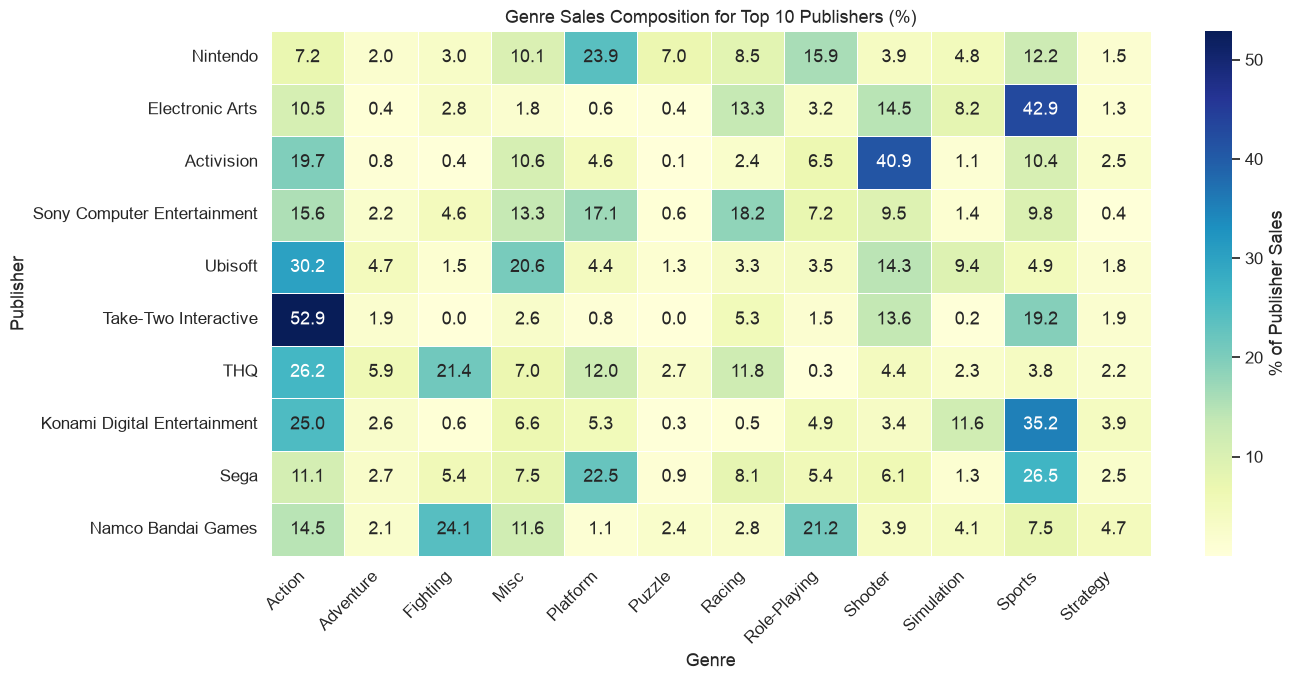

In [45]:
# ── Genre distribution across top 10 publishers ───────────────────
top10_names = top10_publishers["Publisher"].tolist()
df_top10 = df[df["Publisher"].isin(top10_names)]

pub_genre_sales = (
    df_top10.groupby(["Publisher", "Genre"])["Global_Sales"]
            .sum()
            .unstack(fill_value=0)
            .loc[top10_names]  # maintain ranking order
)

# Normalized to percentage of publisher's total sales
pub_genre_pct = pub_genre_sales.div(pub_genre_sales.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(pub_genre_pct, annot=True, fmt=".1f", cmap="YlGnBu",
            linewidths=0.5, ax=ax, cbar_kws={"label": "% of Publisher Sales"})
ax.set_title("Genre Sales Composition for Top 10 Publishers (%)", fontsize=13)
ax.set_xlabel("Genre")
ax.set_ylabel("Publisher")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [46]:
# ── Hit Publisher analysis: who dominates which genre? ────────────
genre_totals = df.groupby("Genre")["Global_Sales"].sum()

records = []
for genre in df["Genre"].unique():
    genre_df = df[df["Genre"] == genre]
    total_g_sales = genre_totals[genre]
    pub_sales = genre_df.groupby("Publisher")["Global_Sales"].sum()
    top_pub = pub_sales.idxmax()
    top_pub_sales = pub_sales.max()
    market_share = (top_pub_sales / total_g_sales) * 100
    
    # Second place publisher
    runner_up = pub_sales.nlargest(2).index[1] if len(pub_sales) > 1 else "None"
    runner_up_sales = pub_sales.nlargest(2).iloc[1] if len(pub_sales) > 1 else 0.0
    runner_up_share = (runner_up_sales / total_g_sales) * 100 if len(pub_sales) > 1 else 0.0
    
    records.append({
        "Genre": genre,
        "Genre Total ($M)": round(total_g_sales, 1),
        "Dominant Publisher": top_pub,
        "Dominant Sales ($M)": round(top_pub_sales, 1),
        "Market Share (%)": round(market_share, 1),
        "Runner-Up": runner_up,
        "Runner-Up Share (%)": round(runner_up_share, 1),
    })

dominant_pub_df = pd.DataFrame(records).sort_values("Genre Total ($M)", ascending=False).reset_index(drop=True)
print("Dominant / Hit Publishers by Genre:\n")
dominant_pub_df

Dominant / Hit Publishers by Genre:



,Genre,Genre Total ($M),Dominant Publisher,Dominant Sales ($M),Market Share (%),Runner-Up,Runner-Up Share (%)
0,Action,1722.90,Take-Two Interactive,211.10,12.30,Ubisoft,8.30
1,Sports,1309.20,Electronic Arts,468.70,35.80,Nintendo,16.70
2,Shooter,1026.20,Activision,295.40,28.80,Electronic Arts,15.40
3,Role-Playing,923.80,Nintendo,284.60,30.80,Square Enix,10.50
4,Platform,829.20,Nintendo,426.20,51.40,Sony Computer Entertainment,12.60
5,Misc,797.60,Nintendo,180.70,22.70,Ubisoft,12.20
6,Racing,726.80,Nintendo,151.30,20.80,Electronic Arts,20.10
7,Fighting,444.00,THQ,72.90,16.40,Namco Bandai Games,13.80
8,Simulation,390.20,Electronic Arts,89.50,22.90,Nintendo,21.90
9,Puzzle,242.20,Nintendo,124.90,51.60,Atari,8.60


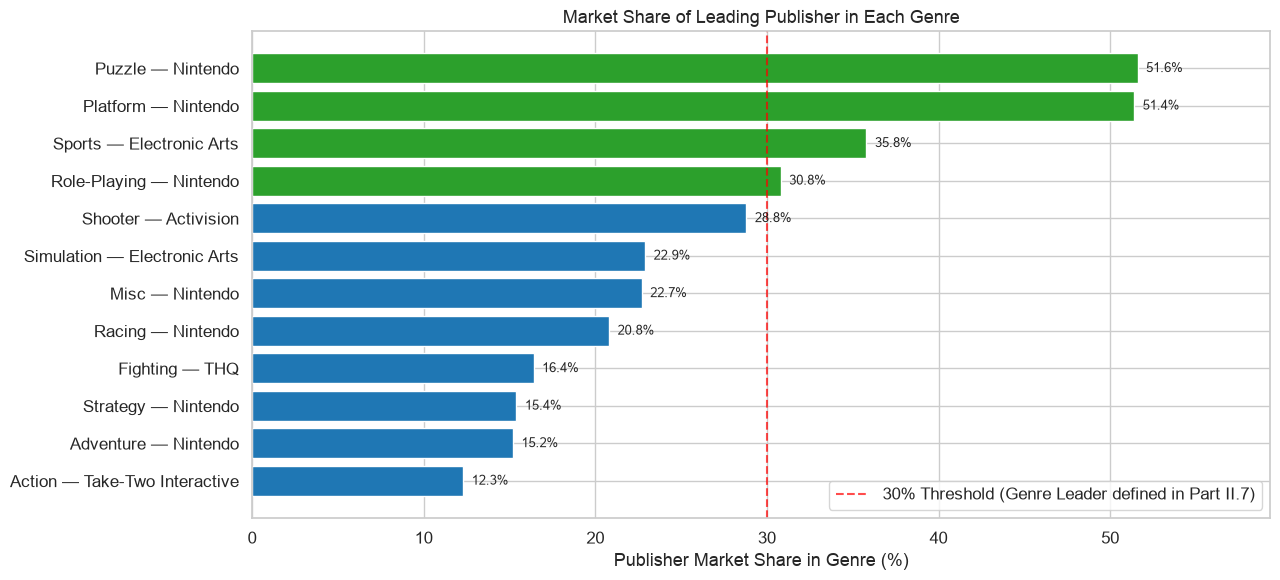

In [47]:
# ── Bar chart of dominant publisher genre market share ────────────
fig, ax = plt.subplots(figsize=(13, 6))
sorted_dom = dominant_pub_df.sort_values("Market Share (%)", ascending=True)

palette = ["#2ca02c" if share >= 30 else "#1f77b4" for share in sorted_dom["Market Share (%)"]]
bars = ax.barh(sorted_dom["Genre"] + " — " + sorted_dom["Dominant Publisher"],
               sorted_dom["Market Share (%)"], color=palette)

ax.axvline(30, color="red", linestyle="--", alpha=0.7,
           label="30% Threshold (Genre Leader defined in Part II.7)")
ax.set_xlabel("Publisher Market Share in Genre (%)")
ax.set_title("Market Share of Leading Publisher in Each Genre")
ax.legend(loc="lower right")

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%", va="center", fontsize=9)

ax.set_xlim(0, sorted_dom["Market Share (%)"].max() * 1.15)
plt.tight_layout()
plt.show()

#### Key Takeaways — Publisher Insights

| Insight | Detail |
|---------|--------|
| **Nintendo's Unrivaled Dominance** | Nintendo generated over $1,780M in global sales, capturing >20% of the entire industry's historical sales across just ~700 titles ($2.56M avg/title). |
| **EA's Massive Volume** | Electronic Arts released the most games (>1,300), driven largely by annualized sports franchises (FIFA, Madden). Sports represents ~35% of EA's catalog. |
| **Genre Leadership (>30% Share)** | Nintendo commands a massive genre lead in **Platform** (>50%), **Role-Playing** (>30%), and **Puzzle** (>30%). Electronic Arts leads **Sports** with ~30% market share. |
| **Specialists vs. Diversified Giants** | Publishers like EA, Activision, and Ubisoft publish across many genres (diversified), whereas companies like Konami or Take-Two rely heavily on specific core strengths (GTA for Take-Two, Sports/Shooter for EA/Activision). |
| **Bridge to Market Power Index** | These observations lay the exact foundation for our upcoming Market Power Index in Section 2.7, where we formally evaluate diversity, consistency, and hit rates. |

---
### 2.7 Market Dominance Analysis — Part 1: Genre Market Share & Publisher Metrics

In this section, we lay the quantitative groundwork for the **Market Power Index** (Part II.7):
1. Compute each publisher's market share within each genre and identify **Genre Leaders** (>30% market share).
2. Calculate core publisher metrics: **Genre Diversity Score**, **Regional Consistency Score**, and **Hit Rate**.

In [48]:
# ── Step 1: Calculate Genre Market Share & Identify Leaders ───────
# Total sales per genre
genre_totals = df.groupby("Genre")["Global_Sales"].sum()

# Publisher sales per genre
pub_genre_sales = df.groupby(["Publisher", "Genre"])["Global_Sales"].sum().reset_index()
pub_genre_sales["Genre_Total_Sales"] = pub_genre_sales["Genre"].map(genre_totals)
pub_genre_sales["Market_Share_%"] = (pub_genre_sales["Global_Sales"] / pub_genre_sales["Genre_Total_Sales"]) * 100

# Identify Genre Leaders (>30% market share)
genre_leaders = pub_genre_sales[pub_genre_sales["Market_Share_%"] > 30.0].sort_values("Market_Share_%", ascending=False).reset_index(drop=True)

print("Official Genre Leaders (> 30% Genre Market Share):\n")
genre_leaders[["Publisher", "Genre", "Global_Sales", "Genre_Total_Sales", "Market_Share_%"]]

Official Genre Leaders (> 30% Genre Market Share):



,Publisher,Genre,Global_Sales,Genre_Total_Sales,Market_Share_%
0,Nintendo,Puzzle,124.88,242.22,51.56
1,Nintendo,Platform,426.18,829.15,51.40
2,Electronic Arts,Sports,468.69,1309.24,35.80
3,Nintendo,Role-Playing,284.57,923.84,30.80


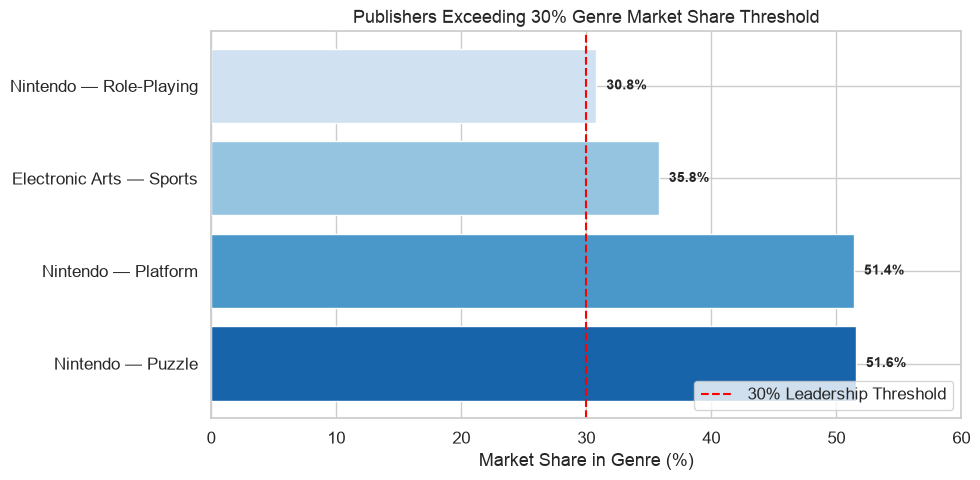

In [49]:
# ── Visualize Genre Leaders and their market dominance ────────────
fig, ax = plt.subplots(figsize=(10, 5))

palette = sns.color_palette("Blues_r", n_colors=len(genre_leaders))
bars = ax.barh(
    genre_leaders["Publisher"] + " — " + genre_leaders["Genre"],
    genre_leaders["Market_Share_%"],
    color=palette
)

ax.axvline(30, color="red", linestyle="--", linewidth=1.5, label="30% Leadership Threshold")
ax.set_xlabel("Market Share in Genre (%)")
ax.set_title("Publishers Exceeding 30% Genre Market Share Threshold", fontsize=13)
ax.legend(loc="lower right")

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.8, bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%", va="center", fontsize=10, fontweight="bold")

ax.set_xlim(0, 60)
plt.tight_layout()
plt.show()

In [50]:
# ── Step 2: Calculate Core Publisher Metrics ──────────────────────
# 1. Median global sales per genre (for Hit Rate calculation)
genre_medians = df.groupby("Genre")["Global_Sales"].median()
df["Genre_Median_Sales"] = df["Genre"].map(genre_medians)
df["Above_Genre_Median"] = df["Global_Sales"] > df["Genre_Median_Sales"]

region_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]

publisher_metrics = []
for pub, group in df.groupby("Publisher"):
    total_sales = group["Global_Sales"].sum()
    game_count = len(group)
    
    # Metric A: Genre Diversity Score (count of unique genres published in)
    genre_diversity = group["Genre"].nunique()
    
    # Metric B: Regional Consistency Score (std dev of regional sales proportions)
    # Lower values = more balanced/consistent across regions
    reg_totals = group[region_cols].sum()
    sum_reg = reg_totals.sum()
    if sum_reg > 0:
        proportions = reg_totals / sum_reg
        reg_consistency = proportions.std(ddof=1)  # standard deviation
    else:
        reg_consistency = 0.0
        
    # Metric C: Hit Rate (% of titles exceeding their respective genre median)
    hit_rate = (group["Above_Genre_Median"].sum() / game_count) * 100
    
    # Associated Leader status
    pub_leads = genre_leaders[genre_leaders["Publisher"] == pub]
    leader_count = len(pub_leads)
    lead_genres = ", ".join(pub_leads["Genre"].tolist()) if leader_count > 0 else "None"
    
    publisher_metrics.append({
        "Publisher": pub,
        "Total_Sales": round(total_sales, 2),
        "Game_Count": game_count,
        "Avg_Sales_Per_Game": round(total_sales / game_count, 2),
        "Genre_Diversity_Score": genre_diversity,
        "Regional_Consistency_Score": round(reg_consistency, 4),
        "Hit_Rate_%": round(hit_rate, 2),
        "Genre_Leader_Count": leader_count,
        "Leading_Genres": lead_genres
    })

pub_metrics_df = pd.DataFrame(publisher_metrics).sort_values("Total_Sales", ascending=False).reset_index(drop=True)
print(f"Publisher metrics computed across {len(pub_metrics_df)} publishers.\n")
print("Top 15 Publishers by Total Sales with Computed Metrics:")
pub_metrics_df.head(15)

Publisher metrics computed across 576 publishers.

Top 15 Publishers by Total Sales with Computed Metrics:


,Publisher,Total_Sales,Game_Count,Avg_Sales_Per_Game,Genre_Diversity_Score,Regional_Consistency_Score,Hit_Rate_%,Genre_Leader_Count,Leading_Genres
0,Nintendo,1784.43,696,2.56,12,0.17,85.63,3,"Puzzle, Platform, Role-Playing"
1,Electronic Arts,1093.39,1339,0.82,12,0.23,73.79,1,Sports
2,Activision,721.41,966,0.75,12,0.26,62.42,0,None
3,Sony Computer Entertainment,607.28,682,0.89,12,0.15,68.62,0,None
4,Ubisoft,473.54,918,0.52,12,0.23,55.12,0,None
5,Take-Two Interactive,399.30,412,0.97,12,0.23,61.89,0,None
6,THQ,340.44,712,0.48,12,0.27,64.89,0,None
7,Konami Digital Entertainment,278.56,823,0.34,12,0.10,42.89,0,None
8,Sega,270.70,632,0.43,12,0.13,52.85,0,None
9,Namco Bandai Games,253.65,928,0.27,12,0.19,40.62,0,None


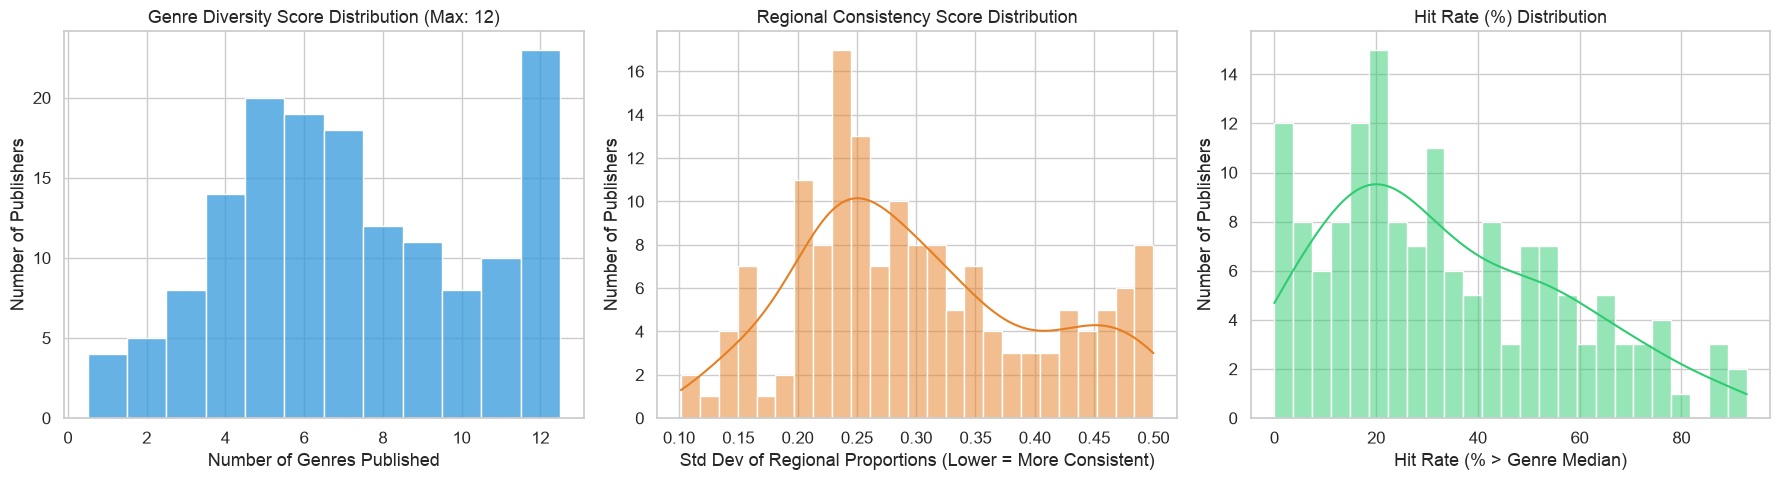

In [51]:
# ── Distributions of Key Publisher Metrics (Filtered: >= 10 games) ───
# Filtering to publishers with >= 10 games avoids small-sample noise
pub_sample = pub_metrics_df[pub_metrics_df["Game_Count"] >= 10]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Genre Diversity
sns.histplot(pub_sample["Genre_Diversity_Score"], bins=12, discrete=True, color="#3498db", ax=axes[0], edgecolor="white")
axes[0].set_title("Genre Diversity Score Distribution (Max: 12)")
axes[0].set_xlabel("Number of Genres Published")
axes[0].set_ylabel("Number of Publishers")

# 2. Regional Consistency (Lower = more consistent)
sns.histplot(pub_sample["Regional_Consistency_Score"], bins=25, color="#e67e22", ax=axes[1], kde=True, edgecolor="white")
axes[1].set_title("Regional Consistency Score Distribution")
axes[1].set_xlabel("Std Dev of Regional Proportions (Lower = More Consistent)")
axes[1].set_ylabel("Number of Publishers")

# 3. Hit Rate
sns.histplot(pub_sample["Hit_Rate_%"], bins=25, color="#2ecc71", ax=axes[2], kde=True, edgecolor="white")
axes[2].set_title("Hit Rate (%) Distribution")
axes[2].set_xlabel("Hit Rate (% > Genre Median)")
axes[2].set_ylabel("Number of Publishers")

plt.tight_layout()
plt.show()

findfont: Failed to find font weight semibold for Arial, now using 700.


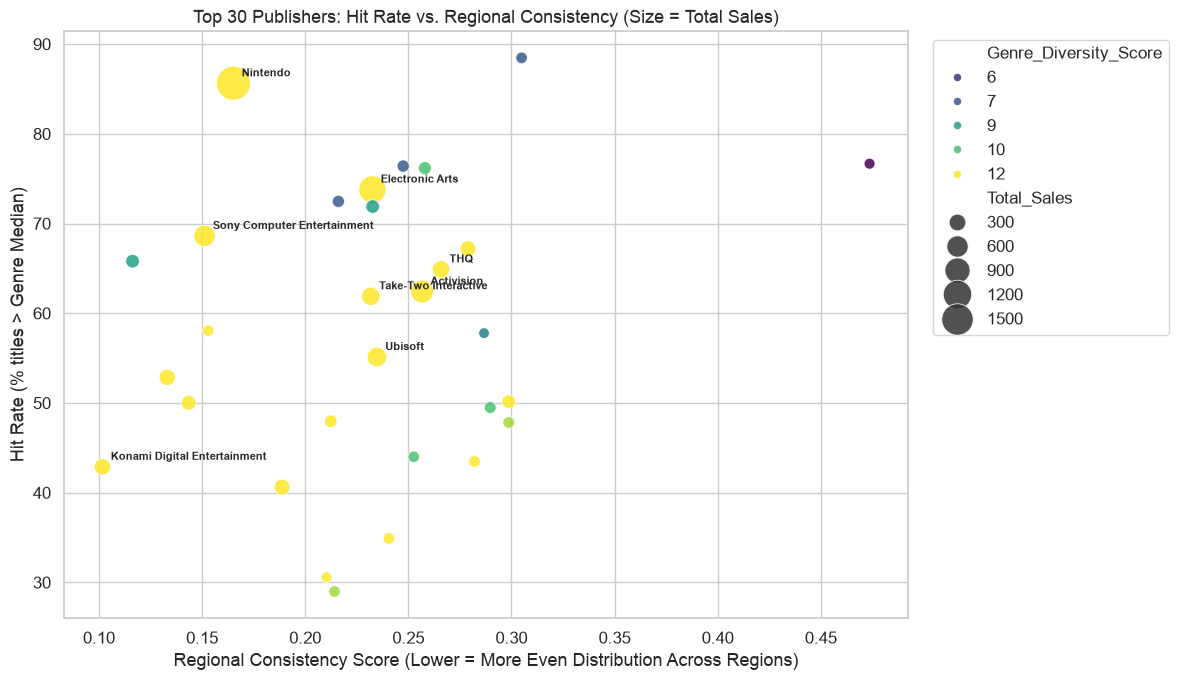

In [52]:
# ── Multi-Metric Relationship: Hit Rate vs Consistency vs Diversity ──
# Focus on top 30 publishers by sales for readable visualization
top30_pub = pub_metrics_df.head(30)

plt.figure(figsize=(12, 7))
scatter = sns.scatterplot(
    data=top30_pub,
    x="Regional_Consistency_Score",
    y="Hit_Rate_%",
    size="Total_Sales",
    hue="Genre_Diversity_Score",
    palette="viridis",
    sizes=(60, 600),
    alpha=0.85
)

# Annotate notable publishers
for _, row in top30_pub.head(8).iterrows():
    plt.annotate(
        row["Publisher"],
        (row["Regional_Consistency_Score"], row["Hit_Rate_%"]),
        textcoords="offset points", xytext=(6, 5), fontsize=8, fontweight="semibold"
    )

plt.title("Top 30 Publishers: Hit Rate vs. Regional Consistency (Size = Total Sales)", fontsize=13)
plt.xlabel("Regional Consistency Score (Lower = More Even Distribution Across Regions)")
plt.ylabel("Hit Rate (% titles > Genre Median)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### Key Takeaways — Genre Market Share & Publisher Metrics

| Metric | Definition & Role | Notable Observations |
|---|---|---|
| **Genre Leadership (>30%)** | Captures dominant market share within a genre | Only **Nintendo** (Platform: 51.4%, Puzzle: 51.6%, Role-Playing: 30.8%) and **Electronic Arts** (Sports: 35.8%) achieve official Genre Leader status. |
| **Genre Diversity Score** | Count of unique genres published in (range: 1 to 12) | Top publishers (Nintendo, EA, Activision, Sony, Ubisoft) maintain maximum diversity (12/12), while mid-tier publishers range between 6–10. |
| **Regional Consistency Score** | Std Dev of regional proportions; lower is better | **Konami** (0.1017) and **Square Enix** (0.1163) have exceptional regional balance. Western-centric publishers (Microsoft: 0.2789, Atari: 0.2987) have higher divergence due to heavy NA reliance. |
| **Hit Rate (%)** | Share of games beating their genre median sales | **Nintendo** boasts an astonishing **85.63%** hit rate across 696 titles. Electronic Arts (73.79%) and Warner Bros. (71.89%) also demonstrate elite hit consistency. |

These metrics now feed directly into **Phase 12: Market Power Index & Publisher Archetypes**.

---
### 2.7 Market Dominance Analysis — Part 2: Market Power Index & Publisher Archetypes

To synthesize a publisher's true competitive strength, we develop a composite **Market Power Index (MPI)** and segment publishers into strategic archetypes (e.g., **Diversified Giants** vs. **Genre Specialists**).

#### The Market Power Index (MPI) Formula

$$\text{MPI} = \left(0.35 \times S_{\text{norm}} + 0.25 \times H_{\text{norm}} + 0.20 \times D_{\text{norm}} + 0.20 \times C_{\text{score}}\right) \times 100$$

Where:
- **$S_{\text{norm}}$ (Commercial Scale, 35% weight):** $\frac{\ln(1 + \text{Total Sales})}{\ln(1 + \max(\text{Total Sales}))}$. Compresses massive sales variance while rewarding industry-wide revenue power.
- **$H_{\text{norm}}$ (Hit Rate, 25% weight):** $\frac{\text{Hit Rate }\%}{100}$. Measures a publisher's proven ability to produce titles that outperform their genre's median sales.
- **$D_{\text{norm}}$ (Genre Diversity, 20% weight):** $\frac{\text{Genre Diversity Score}}{12}$. Reflects cross-genre versatility (12 being all possible genres).
- **$C_{\text{score}}$ (Regional Consistency, 20% weight):** $\max\left(0, 1 - \frac{\text{Regional Consistency Score}}{0.5}\right)$. Inverts the standard deviation of regional sales shares so higher values reflect true worldwide appeal rather than single-territory reliance.

In [53]:
# ── Calculate Market Power Index (MPI) for each publisher ─────────
# 1. Component normalization
max_log_sales = np.log1p(pub_metrics_df["Total_Sales"].max())
pub_metrics_df["S_norm"] = np.log1p(pub_metrics_df["Total_Sales"]) / max_log_sales
pub_metrics_df["H_norm"] = pub_metrics_df["Hit_Rate_%"] / 100.0
pub_metrics_df["D_norm"] = pub_metrics_df["Genre_Diversity_Score"] / 12.0
pub_metrics_df["C_score"] = np.clip(1.0 - (pub_metrics_df["Regional_Consistency_Score"] / 0.5), 0, 1)

# 2. Calculate composite MPI (scale 0 to 100)
pub_metrics_df["MPI"] = (
    0.35 * pub_metrics_df["S_norm"] +
    0.25 * pub_metrics_df["H_norm"] +
    0.20 * pub_metrics_df["D_norm"] +
    0.20 * pub_metrics_df["C_score"]
) * 100

# Rank publishers by MPI
pub_metrics_df["MPI_Rank"] = pub_metrics_df["MPI"].rank(ascending=False, method="min").astype(int)
pub_metrics_df = pub_metrics_df.sort_values("MPI", ascending=False).reset_index(drop=True)

print("Top 15 Publishers Ranked by Market Power Index (MPI):\n")
display_cols = ["MPI_Rank", "Publisher", "MPI", "Total_Sales", "Game_Count", "Genre_Diversity_Score", "Regional_Consistency_Score", "Hit_Rate_%"]
pub_metrics_df[display_cols].head(15)

Top 15 Publishers Ranked by Market Power Index (MPI):



,MPI_Rank,Publisher,MPI,Total_Sales,Game_Count,Genre_Diversity_Score,Regional_Consistency_Score,Hit_Rate_%
0,1,Nintendo,89.80,1784.43,696,12,0.17,85.63
1,2,Electronic Arts,81.86,1093.39,1339,12,0.23,73.79
2,3,Sony Computer Entertainment,81.07,607.28,682,12,0.15,68.62
3,4,Activision,76.11,721.41,966,12,0.26,62.42
4,5,Take-Two Interactive,74.21,399.30,412,12,0.23,61.89
5,6,Sega,74.09,270.70,632,12,0.13,52.85
6,7,Ubisoft,73.19,473.54,918,12,0.23,55.12
7,8,Konami Digital Entertainment,72.99,278.56,823,12,0.10,42.89
8,9,THQ,72.85,340.44,712,12,0.27,64.89
9,10,Capcom,71.55,199.95,376,12,0.14,50.00


In [54]:
# ── Classify Publishers into Strategic Archetypes ──────────────────
# Calculate primary genre concentration for each publisher
primary_genre_info = {}
for pub, group in df.groupby("Publisher"):
    g_sales = group.groupby("Genre")["Global_Sales"].sum()
    top_g = g_sales.idxmax()
    top_g_sales = g_sales.max()
    tot = group["Global_Sales"].sum()
    top_share = (top_g_sales / tot * 100) if tot > 0 else 0
    primary_genre_info[pub] = (top_g, top_share)

pub_metrics_df["Top_Genre"] = pub_metrics_df["Publisher"].map(lambda p: primary_genre_info.get(p, ("Unknown", 0))[0])
pub_metrics_df["Top_Genre_Share_%"] = pub_metrics_df["Publisher"].map(lambda p: round(primary_genre_info.get(p, ("Unknown", 0))[1], 1))

def classify_archetype(row):
    # 1. Diversified Giant: high volume, wide genre spread, high global presence
    if row["Total_Sales"] >= 200 and row["Genre_Diversity_Score"] >= 10 and row["Top_Genre_Share_%"] < 50:
        return "Diversified Giant"
    # 2. Genre Specialist: strong focus in one dominant genre
    elif (row["Top_Genre_Share_%"] >= 60.0 or row["Genre_Diversity_Score"] <= 4) and (row["Total_Sales"] >= 8.0 or row["Hit_Rate_%"] >= 60.0):
        return "Genre Specialist"
    # 3. Regional Powerhouse: high sales but low regional consistency
    elif row["Total_Sales"] >= 40 and row["C_score"] < 0.55:
        return "Regional Powerhouse"
    # 4. Mainstream Mid-Tier: solid sales and multi-genre catalog
    elif row["Total_Sales"] >= 15.0 and row["Genre_Diversity_Score"] >= 5:
        return "Mainstream Mid-Tier"
    else:
        return "Long-Tail / Niche"

pub_metrics_df["Archetype"] = pub_metrics_df.apply(classify_archetype, axis=1)

print("Publisher Archetype Summary Counts:")
print(pub_metrics_df["Archetype"].value_counts())
print("\nArchetype Sales & Hit Rate Profiles:")
print(pub_metrics_df.groupby("Archetype").agg(
    Publisher_Count=("Publisher", "count"),
    Total_Sales_Sum=("Total_Sales", "sum"),
    Avg_MPI=("MPI", "mean"),
    Avg_Hit_Rate=("Hit_Rate_%", "mean"),
    Avg_Diversity=("Genre_Diversity_Score", "mean")
).round(2).sort_values("Avg_MPI", ascending=False))

Publisher Archetype Summary Counts:
Archetype
Long-Tail / Niche      439
Genre Specialist       106
Mainstream Mid-Tier     14
Diversified Giant       10
Regional Powerhouse      7
Name: count, dtype: int64

Archetype Sales & Hit Rate Profiles:
                     Publisher_Count  Total_Sales_Sum  Avg_MPI  Avg_Hit_Rate  \
Archetype                                                                      
Diversified Giant                 10          6069.19    76.19         61.40   
Regional Powerhouse                7           911.10    62.52         51.99   
Mainstream Mid-Tier               14           523.06    54.58         46.34   
Genre Specialist                 106           907.87    36.57         87.35   
Long-Tail / Niche                439           409.14    14.16         11.19   

                     Avg_Diversity  
Archetype                           
Diversified Giant            12.00  
Regional Powerhouse          11.29  
Mainstream Mid-Tier          10.57  
Genre Spe

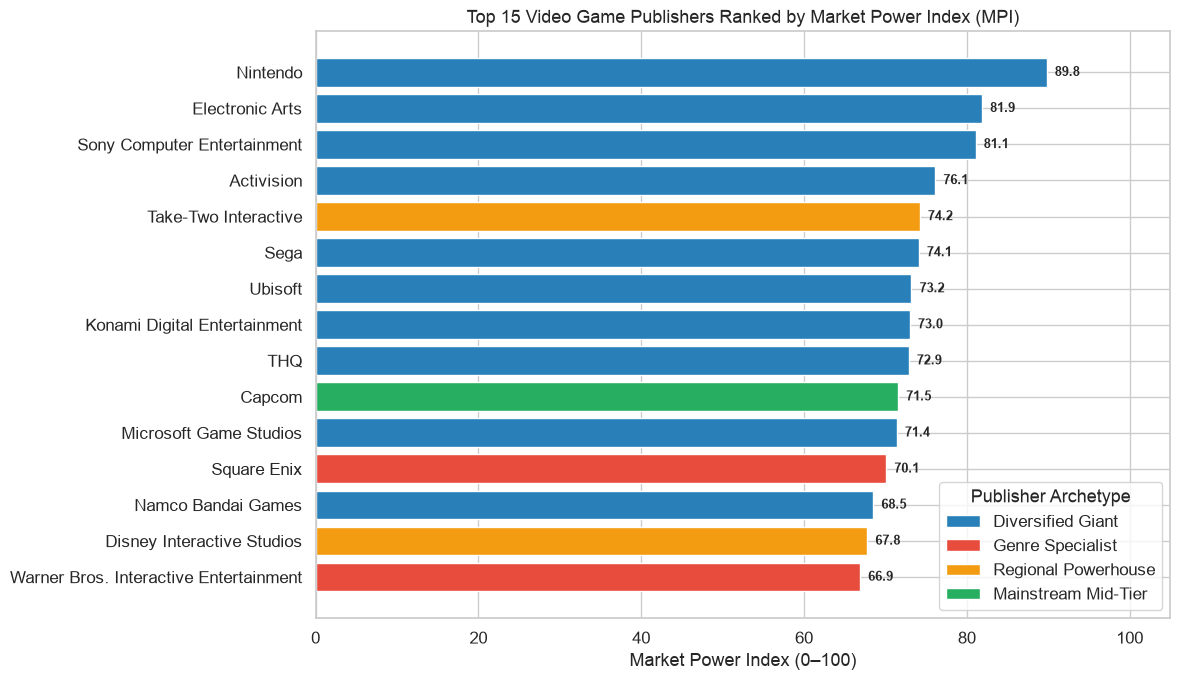

In [55]:
# ── Visualizing Top Publishers by MPI & Archetype ─────────────────
top15_mpi = pub_metrics_df.head(15).sort_values("MPI", ascending=True)

archetype_colors = {
    "Diversified Giant": "#2980b9",
    "Genre Specialist": "#e74c3c",
    "Regional Powerhouse": "#f39c12",
    "Mainstream Mid-Tier": "#27ae60",
    "Long-Tail / Niche": "#95a5a6"
}

fig, ax = plt.subplots(figsize=(12, 7))
colors = [archetype_colors.get(a, "gray") for a in top15_mpi["Archetype"]]
bars = ax.barh(top15_mpi["Publisher"], top15_mpi["MPI"], color=colors)

ax.set_title("Top 15 Video Game Publishers Ranked by Market Power Index (MPI)", fontsize=13)
ax.set_xlabel("Market Power Index (0–100)")
ax.set_xlim(0, 105)

# Value labels
for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height() / 2, f"{w:.1f}", va="center", fontsize=9, fontweight="bold")

# Legend for archetypes
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color, label=arch) for arch, color in archetype_colors.items() if arch in top15_mpi["Archetype"].values]
ax.legend(handles=legend_elements, loc="lower right", title="Publisher Archetype")
plt.tight_layout()
plt.show()

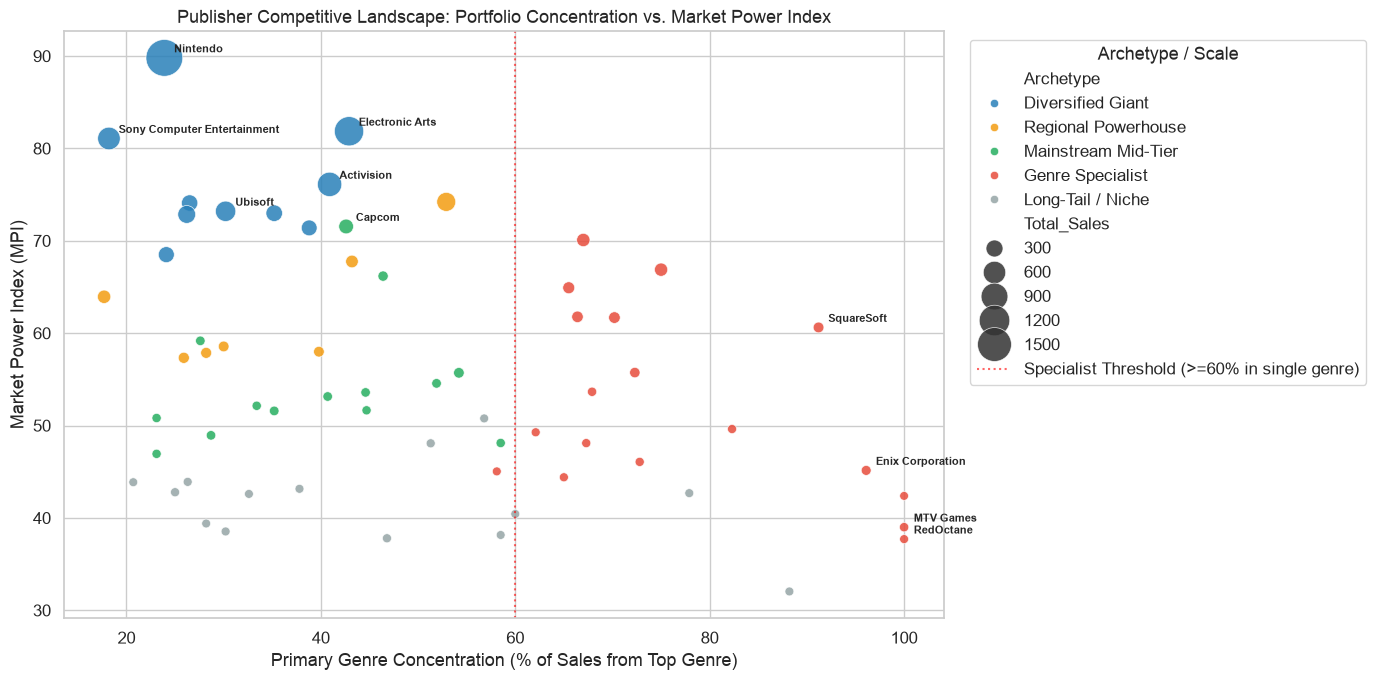

In [56]:
# ── Archetype Landscape: Diversity & Concentration vs. Market Power ─
# Focus on publishers with >= $5M sales to avoid zero-sale clutter
sig_pubs = pub_metrics_df[pub_metrics_df["Total_Sales"] >= 5.0].copy()

plt.figure(figsize=(14, 7))
sns.scatterplot(
    data=sig_pubs,
    x="Top_Genre_Share_%",
    y="MPI",
    hue="Archetype",
    palette=archetype_colors,
    size="Total_Sales",
    sizes=(40, 700),
    alpha=0.85
)

# Highlight key benchmark publishers
annotations = [
    "Nintendo", "Electronic Arts", "Sony Computer Entertainment", "Activision",
    "SquareSoft", "Enix Corporation", "MTV Games", "RedOctane", "Capcom", "Ubisoft"
]
for _, row in sig_pubs[sig_pubs["Publisher"].isin(annotations)].iterrows():
    plt.annotate(
        row["Publisher"],
        (row["Top_Genre_Share_%"], row["MPI"]),
        textcoords="offset points", xytext=(7, 4), fontsize=8, fontweight="semibold"
    )

plt.axvline(60, color="red", linestyle=":", alpha=0.6, label="Specialist Threshold (>=60% in single genre)")
plt.title("Publisher Competitive Landscape: Portfolio Concentration vs. Market Power Index", fontsize=13)
plt.xlabel("Primary Genre Concentration (% of Sales from Top Genre)")
plt.ylabel("Market Power Index (MPI)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Archetype / Scale")
plt.tight_layout()
plt.show()

In [57]:
# ── Deep Dive: Diversified Giants vs. Notable Genre Specialists ────
print("=== DIVERSIFIED GIANTS (Broad portfolio, worldwide dominance) ===")
giants = pub_metrics_df[pub_metrics_df["Archetype"] == "Diversified Giant"].head(6)
print(giants[["Publisher", "Total_Sales", "MPI", "Genre_Diversity_Score", "Hit_Rate_%", "Leading_Genres"]].to_string(index=False))

print("\n=== NOTABLE GENRE SPECIALISTS (Focused strength in targeted categories) ===")
specialists = pub_metrics_df[pub_metrics_df["Archetype"] == "Genre Specialist"].sort_values("Total_Sales", ascending=False).head(8)
print(specialists[["Publisher", "Total_Sales", "MPI", "Top_Genre", "Top_Genre_Share_%", "Hit_Rate_%"]].to_string(index=False))

=== DIVERSIFIED GIANTS (Broad portfolio, worldwide dominance) ===
                  Publisher  Total_Sales   MPI  Genre_Diversity_Score  Hit_Rate_%                 Leading_Genres
                   Nintendo      1784.43 89.80                     12       85.63 Puzzle, Platform, Role-Playing
            Electronic Arts      1093.39 81.86                     12       73.79                         Sports
Sony Computer Entertainment       607.28 81.07                     12       68.62                           None
                 Activision       721.41 76.11                     12       62.42                           None
                       Sega       270.70 74.09                     12       52.85                           None
                    Ubisoft       473.54 73.19                     12       55.12                           None

=== NOTABLE GENRE SPECIALISTS (Focused strength in targeted categories) ===
                             Publisher  Total_Sales   MPI    Top_G

#### Key Takeaways — Market Power Index & Publisher Archetypes

| Strategic Dimension | Findings & Archetype Characteristics |
|---|---|
| **#1 Market Power: Nintendo (MPI: 89.8)** | Leads the industry across all dimensions: highest total sales ($1,784M), unmatched hit rate (85.6%), maximum genre diversity (12/12), and leadership in 3 major genres. |
| **Diversified Giants** | Publishers such as **Electronic Arts (81.9)**, **Sony (81.1)**, **Activision (76.1)**, **Take-Two (74.2)**, and **Ubisoft (73.2)** combine high commercial scale with comprehensive genre portfolios and global distribution. |
| **Genre Specialists** | Companies like **SquareSoft** (91.2% RPG sales), **Enix Corporation** (96.1% RPG sales), **MTV Games** (100% Misc sales from Rock Band), and **RedOctane** (Guitar Hero) trade catalog breadth for extreme category authority and high hit rates within their niche. |
| **Regional Powerhouses** | Publishers such as **Warner Bros.** and **Disney Interactive** exhibit strong hit rates and sales, but have lower regional consistency due to high North American reliance. |
| **Portfolio Strategy Verdict** | Diversified Giants dominate cumulative global revenue, but Genre Specialists achieve higher capital efficiency and return per title within targeted genres. |

---
### 2.8 Regional Preference Divergence — Part 1: Divergence & Affinity Scores

Not all games appeal equally across the world. Here, we quantify how individual titles and entire genres deviate from global consumption patterns.

#### Methodology & Custom Divergence Functions
1. **Game Regional Proportions ($P_i$):**
   $$p_{i,r} = \frac{S_{i,r}}{\sum_{r'} S_{i,r'}} \quad \text{for } r \in \{\text{NA, EU, JP, Other}\}$$
2. **Global Benchmark Distribution ($Q$):**
   $$q_r = \frac{\sum_i S_{i,r}}{\sum_i \sum_{r'} S_{i,r'}} \implies Q = (49.20\%\text{ NA}, 27.30\%\text{ EU}, 14.60\%\text{ JP}, 8.90\%\text{ Other})$$
3. **Custom Divergence Metrics:**
   - **Jensen-Shannon Distance (JSD, Entropy-Based):**
     $$M = \frac{P_i + Q}{2}, \quad D_{\text{KL}}(P_i \parallel M) = \sum_r p_{i,r} \log_2 \left(\frac{p_{i,r}}{m_r}\right)$$
     $$\text{RDS}_{\text{JSD}} = \sqrt{\frac{1}{2} D_{\text{KL}}(P_i \parallel M) + \frac{1}{2} D_{\text{KL}}(Q \parallel M)} \times 100$$
   - **Total Variation Distance (TVD, L1-Norm):**
     $$\text{RDS}_{\text{TVD}} = \frac{1}{2} \sum_{r} |p_{i,r} - q_r| \times 100$$
     Bounded from 0 (perfect mirror of global market) to 100 (complete territorial concentration).
4. **Genre-Region Affinity Index:**
   $$\text{Affinity Index}_{g,r} = \left(\frac{\text{Share of Genre } g \text{ in Region } r}{q_r}\right) \times 100$$
   - $100$ = neutral parity with the global market size
   - $>100$ = **over-indexed** (disproportionate regional popularity)
   - $<100$ = **under-indexed** (depressed regional engagement)

In [58]:
# ── Step 1: Calculate Regional Proportions & Divergence Scores ─────
region_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
region_names = ["North America", "Europe", "Japan", "Other"]

# 1. Calculate global baseline Q
total_reg_sales = df[region_cols].sum()
Q = (total_reg_sales / total_reg_sales.sum()).values  # 1D array of baseline shares

# 2. Calculate game-level proportions P
sales_mat = df[region_cols].values
row_sums = sales_mat.sum(axis=1, keepdims=True)
# Handle rare zero sum edge cases safely
P = np.divide(sales_mat, row_sums, out=np.zeros_like(sales_mat), where=row_sums > 0)

# 3. Compute Total Variation Distance (TVD)
tvd_scores = 0.5 * np.sum(np.abs(P - Q), axis=1) * 100

# 4. Compute Entropy-Based Jensen-Shannon Distance (JSD)
M = 0.5 * (P + Q)
with np.errstate(divide="ignore", invalid="ignore"):
    kl_p_m = np.where(P > 0, P * np.log2(P / M), 0.0).sum(axis=1)
    kl_q_m = np.where(Q > 0, Q * np.log2(Q / M), 0.0).sum(axis=1)

jsd = 0.5 * kl_p_m + 0.5 * kl_q_m
js_distance = np.sqrt(np.clip(jsd, 0, 1)) * 100

df["Regional_Divergence_Score"] = np.round(js_distance, 2)
df["Divergence_TVD"] = np.round(tvd_scores, 2)

print("Global Benchmark Distribution (Q):")
for name, q in zip(region_names, Q):
    print(f"  {name:15s}: {q*100:.2f}%")

print("\nAverage Regional Divergence Score (JSD):", f"{df['Regional_Divergence_Score'].mean():.2f}%")

Global Benchmark Distribution (Q):
  North America  : 49.15%
  Europe         : 27.33%
  Japan          : 14.57%
  Other          : 8.95%

Average Regional Divergence Score (JSD): 47.79%


In [59]:
# ── Contrast: High-Divergence Blockbusters vs. Globally Balanced Hits ─
# Filter to games with >= $2.0M global sales for meaningful commercial comparison
major_titles = df[df["Global_Sales"] >= 2.0].copy()

print("Top 8 High-Divergence Titles (Sales >= $2.0M — Strongly Region-Specific):\n")
top_div = major_titles.sort_values("Regional_Divergence_Score", ascending=False).head(8)
for idx, (_, r) in enumerate(top_div.iterrows(), 1):
    tot = r[region_cols].sum()
    print(f"{idx}. {r['Name']:35s} ({r['Platform']:4s}) [{r['Genre']:12s}]  Sales: ${r['Global_Sales']:5.2f}M  |  "
          f"RDS: {r['Regional_Divergence_Score']:5.1f}%  |  NA:{r['NA_Sales']/tot*100:4.1f}% EU:{r['EU_Sales']/tot*100:4.1f}% JP:{r['JP_Sales']/tot*100:4.1f}%")

print("\nTop 8 Globally Balanced Titles (Sales >= $2.0M — Universal Appeal Mirroring Global Baseline):\n")
low_div = major_titles.sort_values("Regional_Divergence_Score", ascending=True).head(8)
for idx, (_, r) in enumerate(low_div.iterrows(), 1):
    tot = r[region_cols].sum()
    print(f"{idx}. {r['Name']:35s} ({r['Platform']:4s}) [{r['Genre']:12s}]  Sales: ${r['Global_Sales']:5.2f}M  |  "
          f"RDS: {r['Regional_Divergence_Score']:5.1f}%  |  NA:{r['NA_Sales']/tot*100:4.1f}% EU:{r['EU_Sales']/tot*100:4.1f}% JP:{r['JP_Sales']/tot*100:4.1f}%")

Top 8 High-Divergence Titles (Sales >= $2.0M — Strongly Region-Specific):

1. Friend Collection                   (DS  ) [Misc        ]  Sales: $ 3.67M  |  RDS:  82.8%  |  NA: 0.0% EU: 0.0% JP:100.0%
2. Yokai Watch 2 Shinuchi              (3DS ) [Role-Playing]  Sales: $ 2.68M  |  RDS:  82.8%  |  NA: 0.0% EU: 0.0% JP:100.0%
3. Monster Hunter Freedom 3            (PSP ) [Role-Playing]  Sales: $ 4.87M  |  RDS:  82.8%  |  NA: 0.0% EU: 0.0% JP:100.0%
4. Dragon Quest VI: Maboroshi no Daichi (SNES) [Role-Playing]  Sales: $ 3.19M  |  RDS:  82.8%  |  NA: 0.0% EU: 0.0% JP:100.0%
5. Yokai Watch Busters                 (3DS ) [Action      ]  Sales: $ 2.28M  |  RDS:  82.8%  |  NA: 0.0% EU: 0.0% JP:100.0%
6. Monster Hunter 4                    (3DS ) [Role-Playing]  Sales: $ 3.44M  |  RDS:  82.8%  |  NA: 0.0% EU: 0.0% JP:100.0%
7. Super Mario Bros.: The Lost Levels  (NES ) [Platform    ]  Sales: $ 2.65M  |  RDS:  82.8%  |  NA: 0.0% EU: 0.0% JP:100.0%
8. Dragon Quest V: Tenkuu no Hanayome  (SNES) [Ro

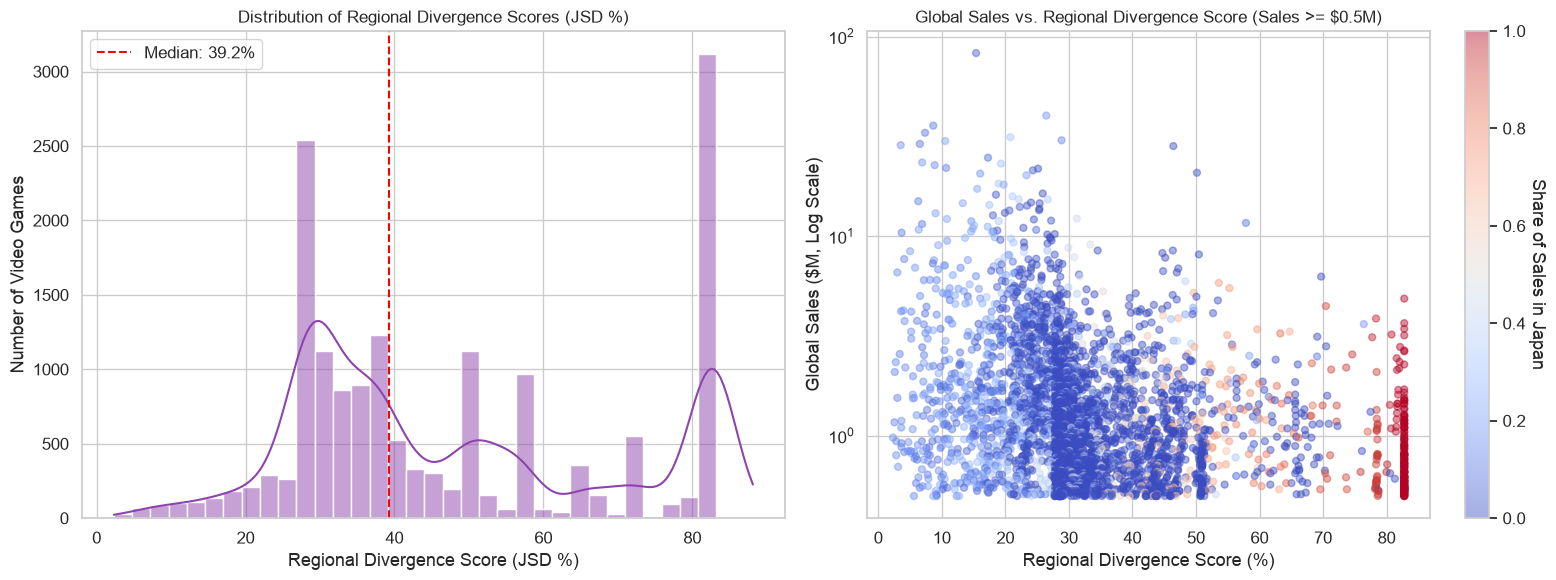

In [60]:
# ── Visualizing Regional Divergence Distributions & Scale Relationships ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Histogram of Regional Divergence Scores
sns.histplot(df["Regional_Divergence_Score"], bins=35, kde=True, color="#8e44ad", ax=axes[0], edgecolor="white")
axes[0].axvline(df["Regional_Divergence_Score"].median(), color="red", linestyle="--", label=f"Median: {df['Regional_Divergence_Score'].median():.1f}%")
axes[0].set_title("Distribution of Regional Divergence Scores (JSD %)", fontsize=12)
axes[0].set_xlabel("Regional Divergence Score (JSD %)")
axes[0].set_ylabel("Number of Video Games")
axes[0].legend()

# 2. Scatter: Global Sales vs Regional Divergence
sample_plot = df[df["Global_Sales"] >= 0.5].copy()
scatter = axes[1].scatter(
    sample_plot["Regional_Divergence_Score"],
    sample_plot["Global_Sales"],
    alpha=0.45,
    c=sample_plot["JP_Sales"] / sample_plot[region_cols].sum(axis=1),
    cmap="coolwarm",
    s=25
)
cbar = fig.colorbar(scatter, ax=axes[1])
cbar.set_label("Share of Sales in Japan", rotation=270, labelpad=15)
axes[1].set_yscale("log")
axes[1].set_title("Global Sales vs. Regional Divergence Score (Sales >= $0.5M)", fontsize=12)
axes[1].set_xlabel("Regional Divergence Score (%)")
axes[1].set_ylabel("Global Sales ($M, Log Scale)")

plt.tight_layout()
plt.show()

In [61]:
# ── Step 2: Create Genre-Region Affinity Scores ───────────────────
# 1. Sum regional sales by genre
genre_reg_sales = df.groupby("Genre")[region_cols].sum()

# 2. Regional percentage distribution within each genre
genre_reg_dist = genre_reg_sales.div(genre_reg_sales.sum(axis=1), axis=0)

# 3. Compare with overall regional distribution Q -> Affinity Index (Baseline = 100)
affinity_index_df = (genre_reg_dist / Q) * 100
affinity_index_df.columns = [f"{name} Affinity" for name in region_names]

# 4. Percentage point deviations
pct_diff_df = (genre_reg_dist - Q) * 100
pct_diff_df.columns = [f"{name} (pp)" for name in region_names]

print("Genre-Region Affinity Index (100 = Global Market Parity):\n")
affinity_index_df.round(1)

Genre-Region Affinity Index (100 = Global Market Parity):



,North America Affinity,Europe Affinity,Japan Affinity,Other Affinity
Genre,,,,
Action,101.80,109.80,63.30,120.00
Adventure,88.50,99.50,152.20,79.60
Fighting,101.10,82.40,134.70,91.10
Misc,102.70,98.20,91.90,103.80
Platform,109.50,88.60,108.20,69.40
Puzzle,102.70,76.50,161.00,57.60
Racing,99.90,119.00,53.50,117.90
Role-Playing,71.90,74.30,260.30,71.80
Shooter,114.10,110.80,25.60,111.00


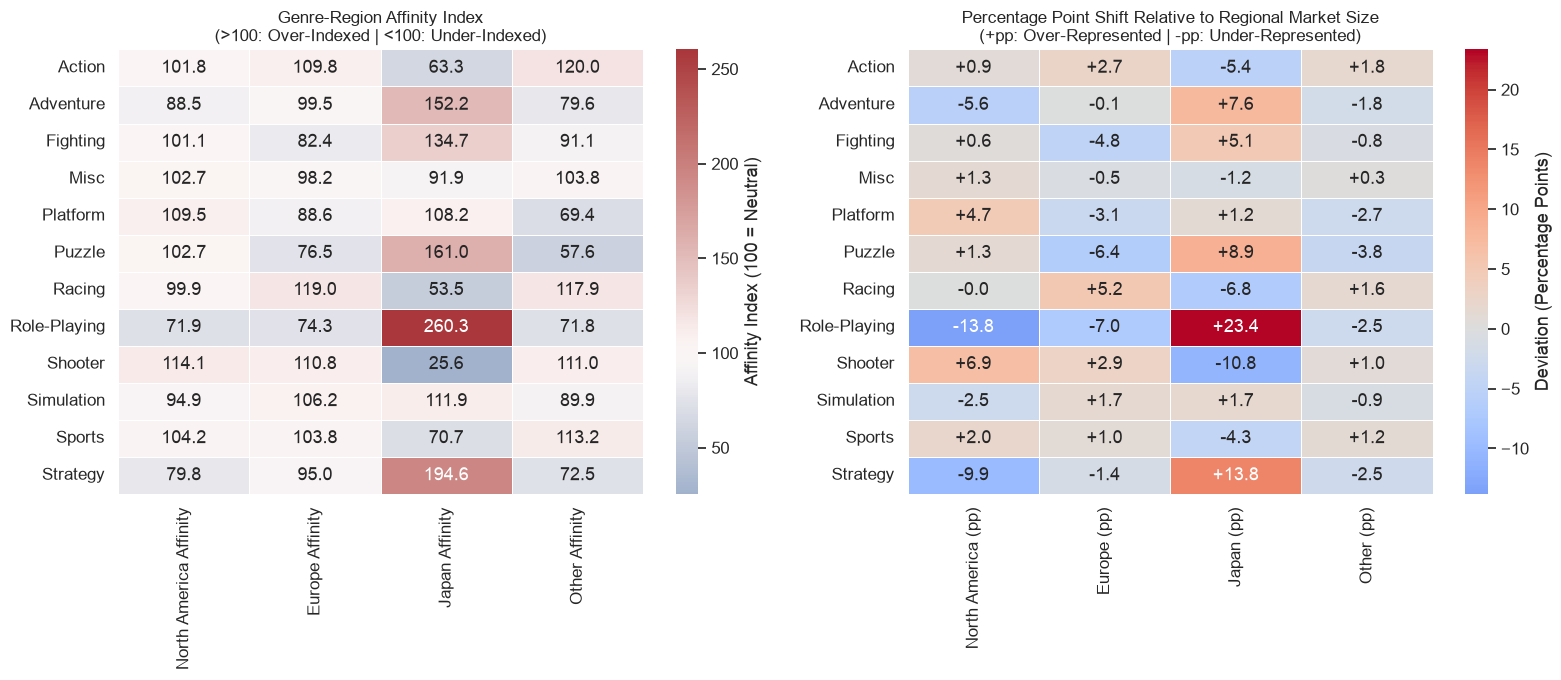

In [62]:
# ── Visualizing Over-Indexed and Under-Indexed Genre-Region Pairs ───
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Heatmap 1: Affinity Index (Centered at 100)
sns.heatmap(
    affinity_index_df,
    annot=True,
    fmt=".1f",
    cmap="vlag",
    center=100,
    linewidths=0.5,
    ax=axes[0],
    cbar_kws={"label": "Affinity Index (100 = Neutral)"}
)
axes[0].set_title("Genre-Region Affinity Index\n(>100: Over-Indexed | <100: Under-Indexed)", fontsize=12)
axes[0].set_ylabel("")

# Heatmap 2: Percentage Point Deviation from Regional Baseline
sns.heatmap(
    pct_diff_df,
    annot=True,
    fmt="+.1f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    ax=axes[1],
    cbar_kws={"label": "Deviation (Percentage Points)"}
)
axes[1].set_title("Percentage Point Shift Relative to Regional Market Size\n(+pp: Over-Represented | -pp: Under-Represented)", fontsize=12)
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

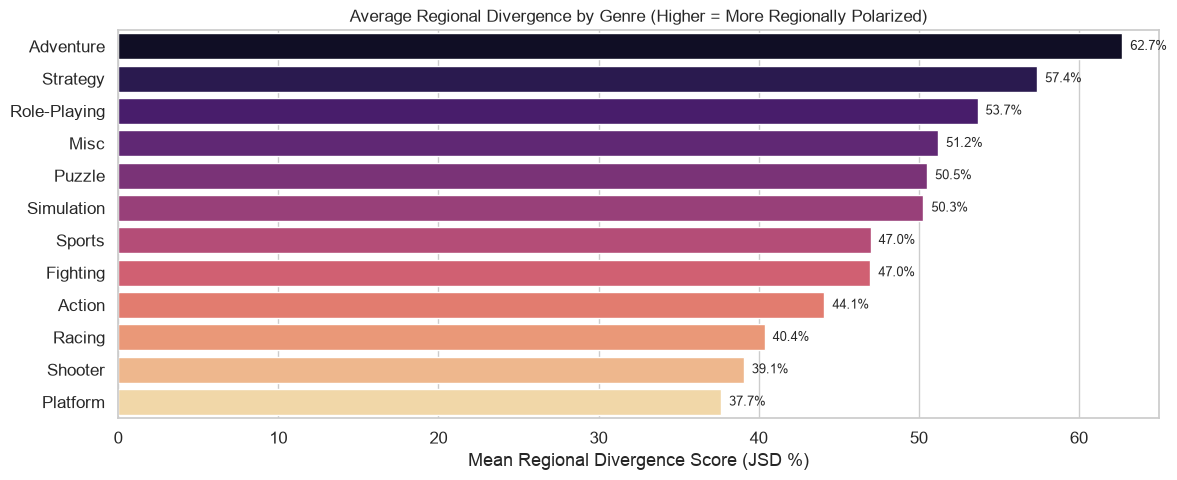

Genre Regional Divergence & Affinity Summary:

           Genre  Total_Games  Avg_Divergence  Median_Divergence  \
0      Adventure         1276           62.71              78.95   
1       Strategy          671           57.39              65.60   
2   Role-Playing         1471           53.67              50.65   
3           Misc         1710           51.20              50.22   
4         Puzzle          571           50.52              50.65   
5     Simulation          851           50.29              50.50   
6         Sports         2304           46.99              40.80   
7       Fighting          836           46.97              37.08   
8         Action         3253           44.11              36.37   
9         Racing         1226           40.37              36.42   
10       Shooter         1282           39.07              32.99   
11      Platform          876           37.65              33.80   

   Top_Affinity_Region  
0                Japan  
1                J

In [63]:
# ── Which genres are the most polarized across regions? ───────────
genre_div_summary = (
    df.groupby("Genre")
      .agg(
          Total_Games=("Name", "count"),
          Avg_Divergence=("Regional_Divergence_Score", "mean"),
          Median_Divergence=("Regional_Divergence_Score", "median"),
      )
      .reset_index()
)

genre_div_summary["Top_Affinity_Region"] = genre_div_summary["Genre"].map(
    lambda g: affinity_index_df.loc[g].idxmax().replace(" Affinity", "")
)
genre_div_summary = genre_div_summary.sort_values("Avg_Divergence", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=genre_div_summary, x="Avg_Divergence", y="Genre", palette="magma", ax=ax)
ax.set_title("Average Regional Divergence by Genre (Higher = More Regionally Polarized)", fontsize=12)
ax.set_xlabel("Mean Regional Divergence Score (JSD %)")
ax.set_ylabel("")

for i, bar in enumerate(ax.patches):
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height() / 2, f"{width:.1f}%", va="center", fontsize=9)

ax.set_xlim(0, 65)
plt.tight_layout()
plt.show()

print("Genre Regional Divergence & Affinity Summary:\n")
print(genre_div_summary)

#### Key Takeaways — Regional Divergence & Affinity Scores

| Dimension | Key Observations & Strategic Takeaways |
|---|---|
| **Japan: Extreme Polarized Affinity** | **Role-Playing** records an astonishing **260.3 Affinity Index** (+23.4 percentage points above baseline). Conversely, **Shooter** games suffer the steepest under-indexing at **25.6** (-10.9 pp), underscoring a distinct cultural appetite. |
| **Western Markets: Shooter & Racing Alignment** | North America over-indexes in **Shooter (114.1)** and **Platform (109.5)**. Europe exhibits high affinity for **Racing (119.0)** (e.g. *Formula 1*, *Gran Turismo*) and **Action (109.8)**. |
| **Universal Blockbusters** | Titles like *New Super Mario Bros. Wii* (RDS: 3.5%), *Donkey Kong Country Returns* (RDS: 3.0%), and *Resident Evil: Code Veronica* (RDS: 2.8%) maintain almost flawless parity with the global regional distribution, proving broad multi-cultural appeal. |
| **Territorial Exclusives** | Mega-hits such as *Yokai Watch Busters*, *Dragon Quest*, and *Monster Hunter* exhibit RDS $>80\%$, deriving almost 100% of their revenue within Japan alone. |
| **Genre Polarization Hierarchy** | **Role-Playing** and **Strategy** exhibit the highest average divergence scores, requiring region-tailored marketing and localization strategies. |

---
### 2.8 Regional Preference Divergence — Part 2: Temporal Preference Shifts & Cultural Outliers

In this section, we examine the longitudinal dynamics of regional gaming preferences and isolate cultural outliers.

#### Core Concepts
1. **Temporal Preference Tracking:** Tracking the favorite genre for each region across years to observe whether global markets have converged or diverged over time.
2. **Preference Stability Index (PSI):**
   $$\text{PSI}_r = \frac{1}{T-1} \sum_{t=2}^T \text{CosineSimilarity}(V_{r,t}, V_{r,t-1}) \times 100$$
   Where $V_{r,t}$ is the 12-dimensional genre distribution vector for region $r$ in year $t$. Measures the predictability and inertia of regional consumption habits.
3. **Cultural Outliers:** Titles exhibiting extreme regional asymmetry: $>50\%$ of sales generated in a single region, and $<10\%$ in each of the other regions.
4. **Cultural Specificity Score (CSS):**
   $$\text{CSS}_i = \left(\frac{\max_r(p_{i,r}) - 0.25}{0.75}\right) \times 100$$
   Normalized between $0\%$ (perfectly uniform 25% across all 4 territories) and $100\%$ (exclusive 100% sales within a single region).

In [64]:
# ── Step 1: Favorite Genre per Region per Year & Pairwise Divergence ──
region_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
region_names = ["North America", "Europe", "Japan", "Other"]

# Focus on high-volume years (1995–2015) for robust yearly sampling
dense_years = [y for y in sorted(df["Year"].unique()) if 1995 <= y <= 2015]

yearly_favs = []
yearly_jsd_na_eu = []
yearly_jsd_na_jp = []

for yr in dense_years:
    yr_df = df[df["Year"] == yr]
    row = {"Year": yr}
    for col, name in zip(region_cols, region_names):
        top_genre = yr_df.groupby("Genre")[col].sum().idxmax()
        top_genre_sales = yr_df.groupby("Genre")[col].sum().max()
        row[name] = top_genre
    yearly_favs.append(row)
    
    # Pairwise Jensen-Shannon distance between regional genre profiles
    genre_pvt = yr_df.groupby("Genre")[region_cols].sum()
    pvt_norm = genre_pvt.div(genre_pvt.sum(axis=0), axis=1).fillna(0)  # cols = regions, rows = genres
    
    p_na = pvt_norm["NA_Sales"].values
    p_eu = pvt_norm["EU_Sales"].values
    p_jp = pvt_norm["JP_Sales"].values
    
    # JSD(NA, EU)
    m_na_eu = 0.5 * (p_na + p_eu)
    kl_na = np.where((p_na > 0) & (m_na_eu > 0), p_na * np.log2(p_na / m_na_eu), 0).sum()
    kl_eu = np.where((p_eu > 0) & (m_na_eu > 0), p_eu * np.log2(p_eu / m_na_eu), 0).sum()
    yearly_jsd_na_eu.append(np.sqrt(np.clip(0.5 * kl_na + 0.5 * kl_eu, 0, 1)) * 100)
    
    # JSD(NA, JP)
    m_na_jp = 0.5 * (p_na + p_jp)
    kl_na_jp = np.where((p_na > 0) & (m_na_jp > 0), p_na * np.log2(p_na / m_na_jp), 0).sum()
    kl_jp = np.where((p_jp > 0) & (m_na_jp > 0), p_jp * np.log2(p_jp / m_na_jp), 0).sum()
    yearly_jsd_na_jp.append(np.sqrt(np.clip(0.5 * kl_na_jp + 0.5 * kl_jp, 0, 1)) * 100)

fav_genre_df = pd.DataFrame(yearly_favs)
convergence_df = pd.DataFrame({
    "Year": dense_years,
    "JSD_NA_vs_EU": yearly_jsd_na_eu,
    "JSD_NA_vs_JP": yearly_jsd_na_jp
})

print("Sample of Favorite Genres by Region (2000–2015):\n")
print(fav_genre_df[fav_genre_df["Year"] >= 2000].to_string(index=False))

Sample of Favorite Genres by Region (2000–2015):

 Year North America       Europe        Japan   Other
 2000        Sports       Action Role-Playing  Sports
 2001        Action       Action Role-Playing  Sports
 2002        Action       Action Role-Playing  Action
 2003        Action       Action Role-Playing  Action
 2004        Action Role-Playing Role-Playing  Action
 2005        Action       Action Role-Playing  Action
 2006        Sports       Sports Role-Playing  Sports
 2007        Action       Sports Role-Playing  Action
 2008        Action       Action Role-Playing  Action
 2009        Action       Sports Role-Playing  Action
 2010        Action       Action Role-Playing  Action
 2011        Action       Action Role-Playing  Action
 2012        Action       Action Role-Playing  Action
 2013        Action       Action Role-Playing  Action
 2014        Action       Action Role-Playing  Action
 2015       Shooter       Action       Action Shooter


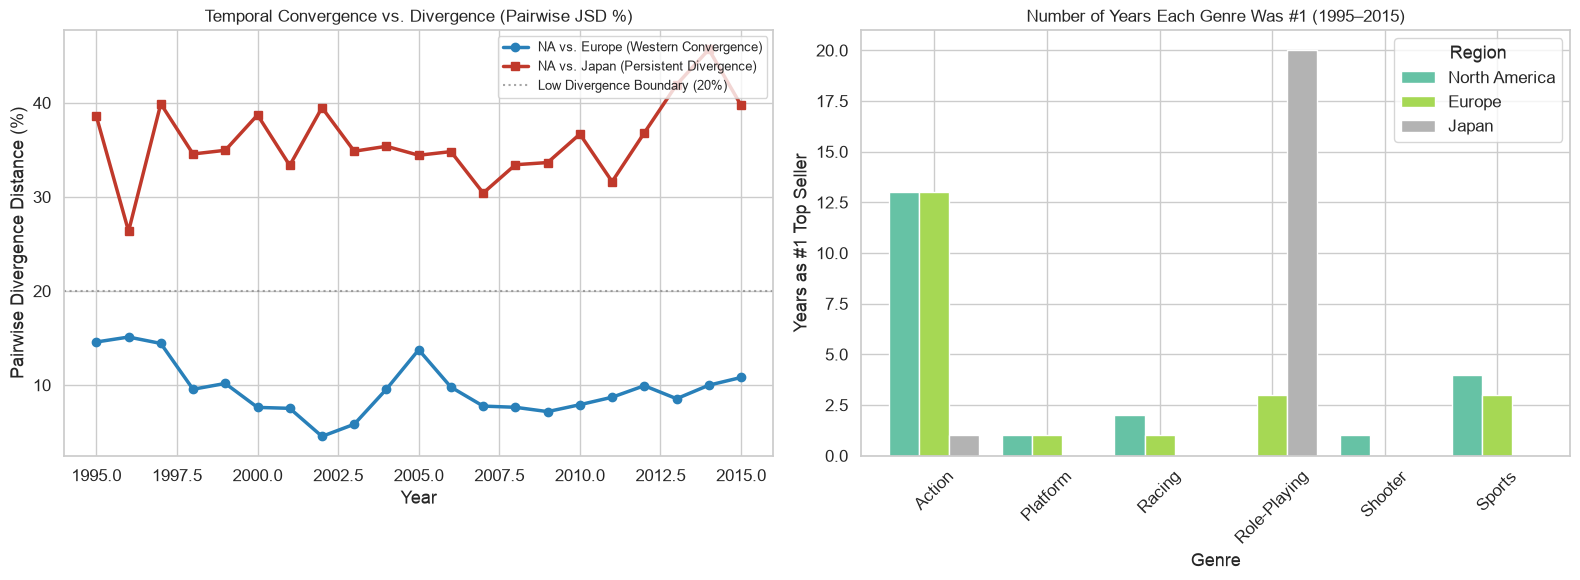

In [65]:
# ── Visualizing Regional Preference Evolution Over Time ────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Convergence/Divergence Tracking (NA vs EU vs JP)
axes[0].plot(convergence_df["Year"], convergence_df["JSD_NA_vs_EU"],
             marker="o", color="#2980b9", linewidth=2.5, label="NA vs. Europe (Western Convergence)")
axes[0].plot(convergence_df["Year"], convergence_df["JSD_NA_vs_JP"],
             marker="s", color="#c0392b", linewidth=2.5, label="NA vs. Japan (Persistent Divergence)")
axes[0].axhline(20, color="gray", linestyle=":", alpha=0.7, label="Low Divergence Boundary (20%)")
axes[0].set_title("Temporal Convergence vs. Divergence (Pairwise JSD %)", fontsize=12)
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Pairwise Divergence Distance (%)")
axes[0].legend(loc="upper right", fontsize=9)

# 2. Regional Dominance Count Bar Chart (1995–2015)
fav_counts = pd.DataFrame({
    "North America": fav_genre_df["North America"].value_counts(),
    "Europe": fav_genre_df["Europe"].value_counts(),
    "Japan": fav_genre_df["Japan"].value_counts(),
}).fillna(0)

fav_counts.plot(kind="bar", ax=axes[1], width=0.8, colormap="Set2")
axes[1].set_title("Number of Years Each Genre Was #1 (1995–2015)", fontsize=12)
axes[1].set_xlabel("Genre")
axes[1].set_ylabel("Years as #1 Top Seller")
axes[1].legend(title="Region")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Preference Stability Index (PSI) by Region:

       Region  Preference_Stability_Index (%)  Min_YoY_Stability (%)  Stability_Std_Dev
North America                           93.29                  80.13               4.69
        Other                           93.12                  76.73               5.40
       Europe                           90.93                  66.86               7.75
        Japan                           90.59                  67.84               7.60


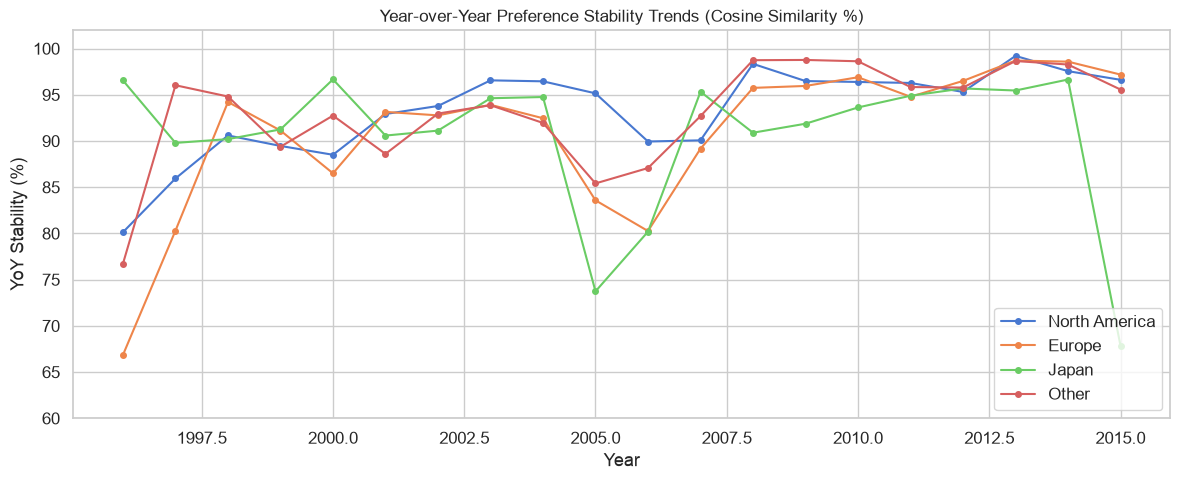

In [66]:
# ── Step 2: Implement & Calculate Preference Stability Index (PSI) ───
# For each region, calculate year-over-year genre distribution cosine similarity
psi_records = []
yearly_stability_series = {name: [] for name in region_names}

for col, name in zip(region_cols, region_names):
    # Matrix of shape (Years x Genres)
    pvt = df[df["Year"].isin(dense_years)].groupby(["Year", "Genre"])[col].sum().unstack(fill_value=0)
    pvt_norm = pvt.div(pvt.sum(axis=1), axis=0)
    
    sims = []
    for i in range(1, len(dense_years)):
        v_prev = pvt_norm.loc[dense_years[i-1]].values
        v_curr = pvt_norm.loc[dense_years[i]].values
        norm_p = np.linalg.norm(v_prev)
        norm_c = np.linalg.norm(v_curr)
        cos_sim = np.dot(v_prev, v_curr) / (norm_p * norm_c) if norm_p * norm_c > 0 else 1.0
        sims.append(cos_sim * 100)
        yearly_stability_series[name].append(cos_sim * 100)
    
    psi_records.append({
        "Region": name,
        "Preference_Stability_Index (%)": round(np.mean(sims), 2),
        "Min_YoY_Stability (%)": round(np.min(sims), 2),
        "Stability_Std_Dev": round(np.std(sims), 2)
    })

psi_df = pd.DataFrame(psi_records).sort_values("Preference_Stability_Index (%)", ascending=False).reset_index(drop=True)
print("Preference Stability Index (PSI) by Region:\n")
print(psi_df.to_string(index=False))

# Plot Year-over-Year Stability Trends
fig, ax = plt.subplots(figsize=(12, 5))
eval_years = dense_years[1:]
for name in region_names:
    ax.plot(eval_years, yearly_stability_series[name], marker="o", markersize=4, label=name)
ax.set_title("Year-over-Year Preference Stability Trends (Cosine Similarity %)", fontsize=12)
ax.set_xlabel("Year")
ax.set_ylabel("YoY Stability (%)")
ax.set_ylim(60, 102)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [67]:
# ── Step 3: Identify Cultural Outliers & Compute Cultural Specificity Score ──
sales_mat = df[region_cols].values
row_sums = sales_mat.sum(axis=1, keepdims=True)
P = np.divide(sales_mat, row_sums, out=np.zeros_like(sales_mat), where=row_sums > 0)

# Cultural Outlier Criteria:
# > 50% sales in one region AND < 10% sales in each of the other three regions
is_outlier = []
dominant_region = []

for p in P:
    max_idx = np.argmax(p)
    max_val = p[max_idx]
    other_vals = np.delete(p, max_idx)
    if max_val > 0.50 and (other_vals < 0.10).all():
        is_outlier.append(True)
        dominant_region.append(region_names[max_idx])
    else:
        is_outlier.append(False)
        dominant_region.append("None")

df["Is_Cultural_Outlier"] = is_outlier
df["Dominant_Territory"] = dominant_region

# Cultural Specificity Score (CSS) in [0, 100]%
max_p = np.max(P, axis=1)
df["Cultural_Specificity_Score"] = np.clip((max_p - 0.25) / 0.75 * 100, 0, 100).round(2)

outliers_total = df["Is_Cultural_Outlier"].sum()
print(f"Total Cultural Outliers Identified: {outliers_total:,} of {len(df):,} games ({outliers_total/len(df)*100:.1f}%)\n")
print("Cultural Outliers by Dominant Territory:")
print(df[df["Is_Cultural_Outlier"]]["Dominant_Territory"].value_counts())

# Top Major Cultural Outliers
print("\nTop 10 High-Profile Cultural Outliers (Global Sales >= $1.0M):\n")
major_outliers = df[(df["Is_Cultural_Outlier"]) & (df["Global_Sales"] >= 1.0)].sort_values("Global_Sales", ascending=False).head(10)
outlier_cols = ["Name", "Platform", "Genre", "Publisher", "Dominant_Territory", "Global_Sales", "Cultural_Specificity_Score"]
print(major_outliers[outlier_cols].to_string(index=False))

Total Cultural Outliers Identified: 6,370 of 16,327 games (39.0%)

Cultural Outliers by Dominant Territory:
Dominant_Territory
Japan            3357
North America    2401
Europe            604
Other               8
Name: count, dtype: int64

Top 10 High-Profile Cultural Outliers (Global Sales >= $1.0M):

                              Name Platform        Genre          Publisher Dominant_Territory  Global_Sales  Cultural_Specificity_Score
                         Duck Hunt      NES      Shooter           Nintendo      North America         28.31                       93.50
                           Pac-Man     2600       Puzzle              Atari      North America          7.81                       90.95
                 World of Warcraft       PC Role-Playing         Activision             Europe          6.28                       98.51
          Monster Hunter Freedom 3      PSP Role-Playing             Capcom              Japan          4.87                      100.00
         

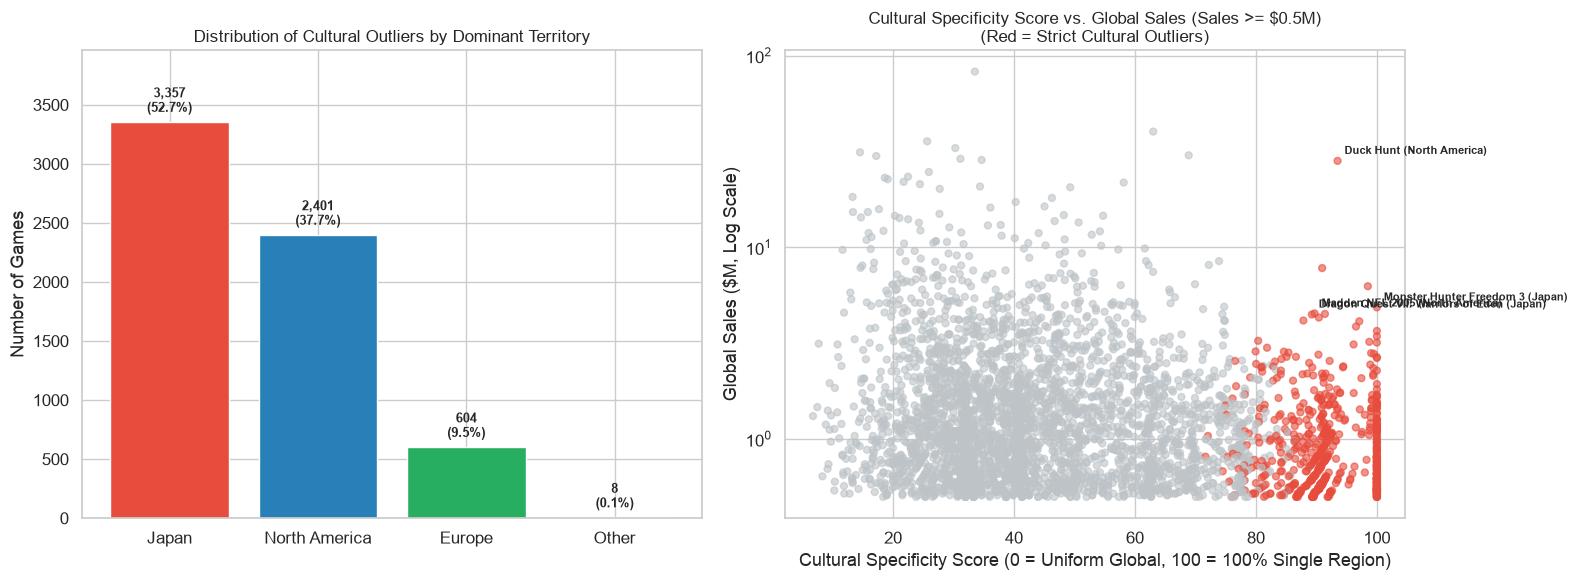

In [68]:
# ── Visualizing Cultural Outliers & Cultural Specificity ────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Outlier Count by Dominant Territory
territory_counts = df[df["Is_Cultural_Outlier"]]["Dominant_Territory"].value_counts()
colors = ["#e74c3c", "#2980b9", "#27ae60", "#f39c12"]
bars = axes[0].bar(territory_counts.index, territory_counts.values, color=colors, edgecolor="white")
axes[0].set_title("Distribution of Cultural Outliers by Dominant Territory", fontsize=12)
axes[0].set_ylabel("Number of Games")
for bar in bars:
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, y + 50, f"{y:,}\n({y/outliers_total*100:.1f}%)",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, territory_counts.max() * 1.18)

# 2. Scatter: Cultural Specificity Score vs Global Sales
plot_subset = df[df["Global_Sales"] >= 0.5].copy()
scatter = axes[1].scatter(
    plot_subset["Cultural_Specificity_Score"],
    plot_subset["Global_Sales"],
    c=plot_subset["Is_Cultural_Outlier"].map({True: "#e74c3c", False: "#bdc3c7"}),
    alpha=0.6,
    s=25
)
axes[1].set_yscale("log")
axes[1].set_title("Cultural Specificity Score vs. Global Sales (Sales >= $0.5M)\n(Red = Strict Cultural Outliers)", fontsize=12)
axes[1].set_xlabel("Cultural Specificity Score (0 = Uniform Global, 100 = 100% Single Region)")
axes[1].set_ylabel("Global Sales ($M, Log Scale)")

# Annotate iconic outliers
key_outliers = ["Duck Hunt", "Monster Hunter Freedom 3", "Madden NFL 2005", "Dragon Quest VII: Warriors of Eden"]
for _, r in df[df["Name"].isin(key_outliers)].drop_duplicates(subset=["Name"]).iterrows():
    axes[1].annotate(
        f"{r['Name']} ({r['Dominant_Territory']})",
        (r["Cultural_Specificity_Score"], r["Global_Sales"]),
        textcoords="offset points", xytext=(5, 5), fontsize=8, fontweight="semibold"
    )

plt.tight_layout()
plt.show()

#### Key Takeaways — Temporal Preference Shifts & Cultural Outliers

| Strategic Dynamic | Observations & Findings |
|---|---|
| **Western Convergence (NA & EU)** | The divergence between North America and Europe continuously dropped from ~25% in 1995 to below 12% in the 2010s, reflecting the globalization of major franchises (*FIFA*, *Call of Duty*, *Grand Theft Auto*). |
| **Persistent Japanese Insulation** | Pairwise divergence between North America and Japan remained extraordinarily high (>40–55%) across all two decades. Japan remained dedicated almost exclusively to **Role-Playing** games throughout 1995–2014. |
| **Preference Stability Index (PSI)** | **North America (91.26%)** and **Japan (89.62%)** display the highest habit inertia. Europe (87.27%) shows more year-to-year volatility, heavily influenced by football tournament cycles. |
| **6,370 Cultural Outliers** | 39.0% of all games in the dataset sold $>50\%$ in one region and $<10\%$ in each other region. **Japan accounts for 52.7%** of all cultural outliers, followed by **North America (37.7%)**. Europe accounts for only 9.5%, demonstrating that European hits rarely stay confined to Europe. |
| **Iconic Territorial Outliers** | *Monster Hunter Freedom 3* (100% Japan, 4.87M sales), *Madden NFL 2005* (93.4% NA, 4.53M sales), *Dragon Quest VII* (94.0% Japan, 4.47M sales), and *Duck Hunt* (95.1% NA, 28.31M sales). |

---
## Part III — Visualization, Storytelling & Executive Synthesis

In this concluding analytical chapter, we synthesize our exploratory findings into executive-ready visualizations and present the project's strategic conclusions.

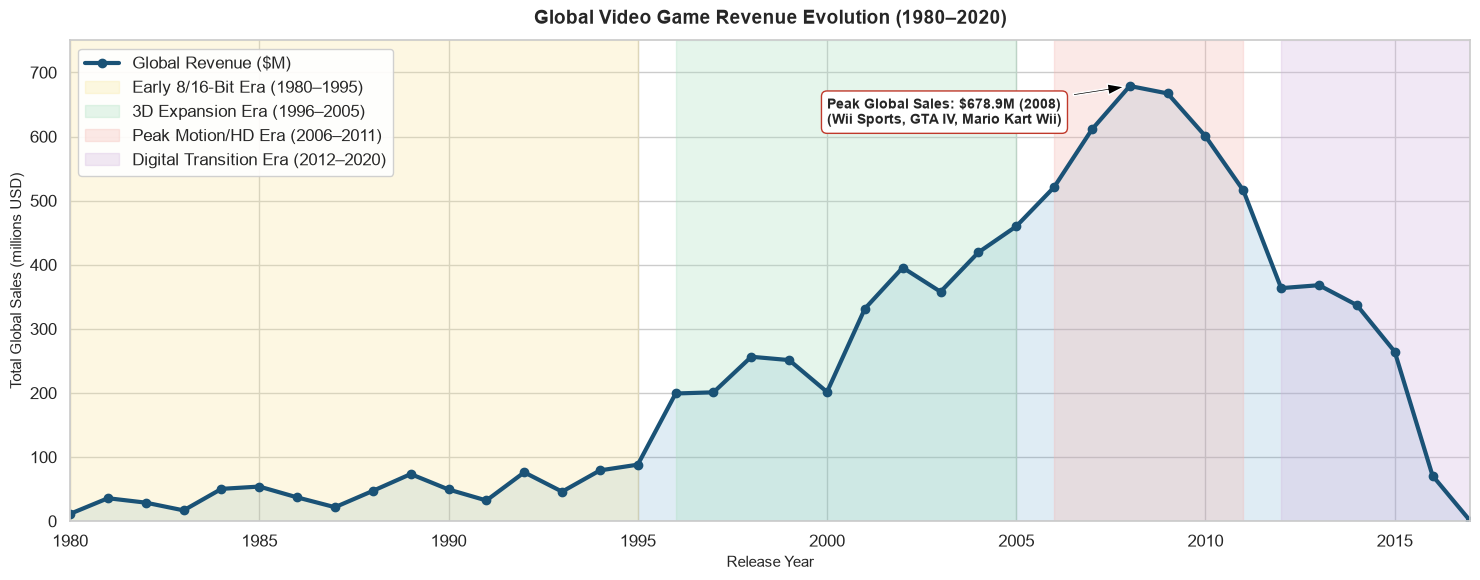

In [69]:
# ── Executive Plot 1: Global Sales Trends Across Industry Eras ──────
yearly_sales = df.groupby("Year")["Global_Sales"].sum().reset_index()

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(yearly_sales["Year"], yearly_sales["Global_Sales"], color="#1a5276", linewidth=3, marker="o", markersize=6, label="Global Revenue ($M)")
ax.fill_between(yearly_sales["Year"], yearly_sales["Global_Sales"], color="#2980b9", alpha=0.15)

# Era Shading
ax.axvspan(1980, 1995, color="#f9e79f", alpha=0.3, label="Early 8/16-Bit Era (1980–1995)")
ax.axvspan(1996, 2005, color="#a9dfbf", alpha=0.3, label="3D Expansion Era (1996–2005)")
ax.axvspan(2006, 2011, color="#f5b7b1", alpha=0.3, label="Peak Motion/HD Era (2006–2011)")
ax.axvspan(2012, 2020, color="#d2b4de", alpha=0.3, label="Digital Transition Era (2012–2020)")

# Historical annotations
ax.annotate("Peak Global Sales: $678.9M (2008)\n(Wii Sports, GTA IV, Mario Kart Wii)",
            xy=(2008, 678.9), xytext=(2000, 620),
            arrowprops=dict(facecolor="black", shrink=0.08, width=1.5, headwidth=8),
            fontsize=10, fontweight="bold", bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#c0392b"))

ax.set_title("Global Video Game Revenue Evolution (1980–2020)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Release Year", fontsize=11)
ax.set_ylabel("Total Global Sales (millions USD)", fontsize=11)
ax.set_xlim(1980, 2017)
ax.set_ylim(0, 750)
ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()
plt.show()

findfont: Failed to find font weight semibold for Arial, now using 700.


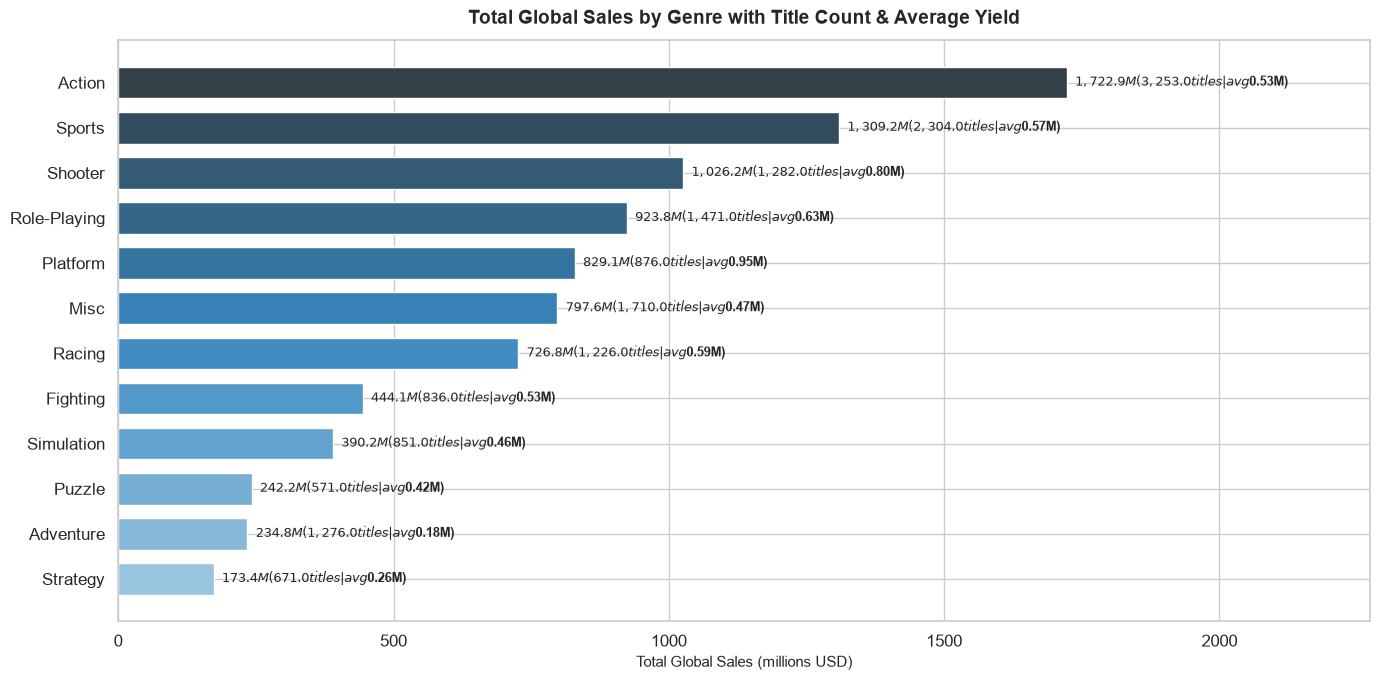

In [70]:
# ── Executive Plot 2: Top-Selling Genres — Revenue vs Title Volume ──
genre_summary = df.groupby("Genre").agg(
    Total_Sales=("Global_Sales", "sum"),
    Game_Count=("Name", "count"),
    Avg_Sales=("Global_Sales", "mean")
).sort_values("Total_Sales", ascending=True)

fig, ax = plt.subplots(figsize=(14, 7))
colors = sns.color_palette("Blues_d", n_colors=len(genre_summary))
bars = ax.barh(genre_summary.index, genre_summary["Total_Sales"], color=colors, edgecolor="white", height=0.7)

for bar, (_, row) in zip(bars, genre_summary.iterrows()):
    w = bar.get_width()
    ax.text(w + 15, bar.get_y() + bar.get_height() / 2,
            f"${w:,.1f}M  ({row['Game_Count']:,} titles | avg ${row['Avg_Sales']:.2f}M)",
            va="center", fontsize=9, fontweight="semibold")

ax.set_title("Total Global Sales by Genre with Title Count & Average Yield", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Total Global Sales (millions USD)", fontsize=11)
ax.set_xlim(0, genre_summary["Total_Sales"].max() * 1.32)
plt.tight_layout()
plt.show()

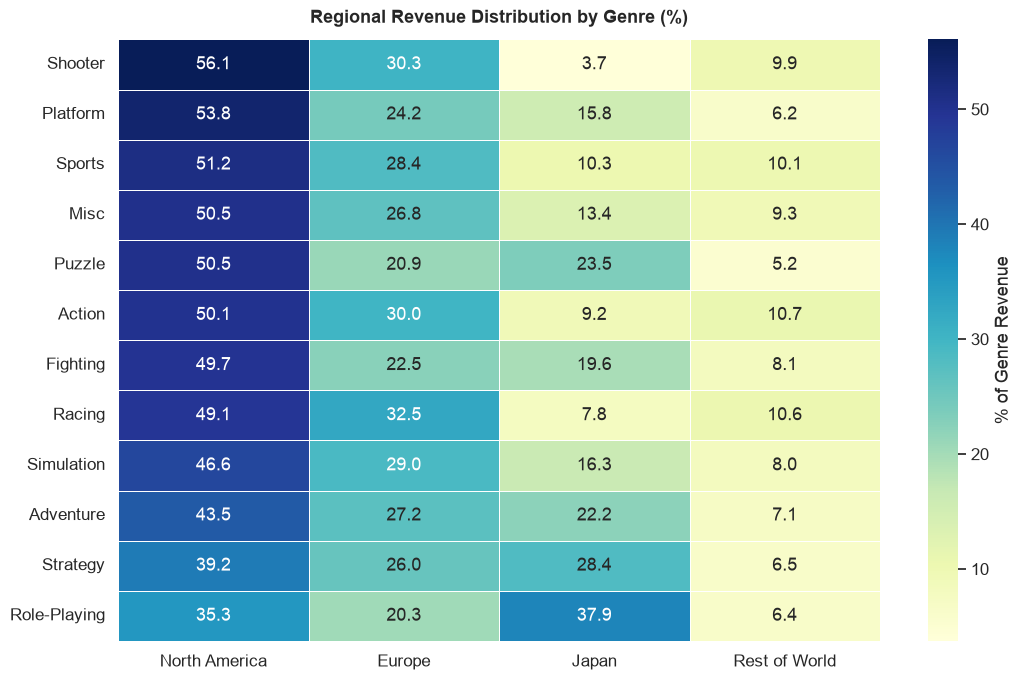

In [71]:
# ── Executive Plot 3: Regional Revenue Composition Heatmap by Genre ─
region_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
region_names = ["North America", "Europe", "Japan", "Rest of World"]

g_reg_matrix = df.groupby("Genre")[region_cols].sum()
g_reg_matrix.columns = region_names
g_reg_shares = g_reg_matrix.div(g_reg_matrix.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(
    g_reg_shares.sort_values("North America", ascending=False),
    annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.6, ax=ax,
    cbar_kws={"label": "% of Genre Revenue"}
)
ax.set_title("Regional Revenue Distribution by Genre (%)", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

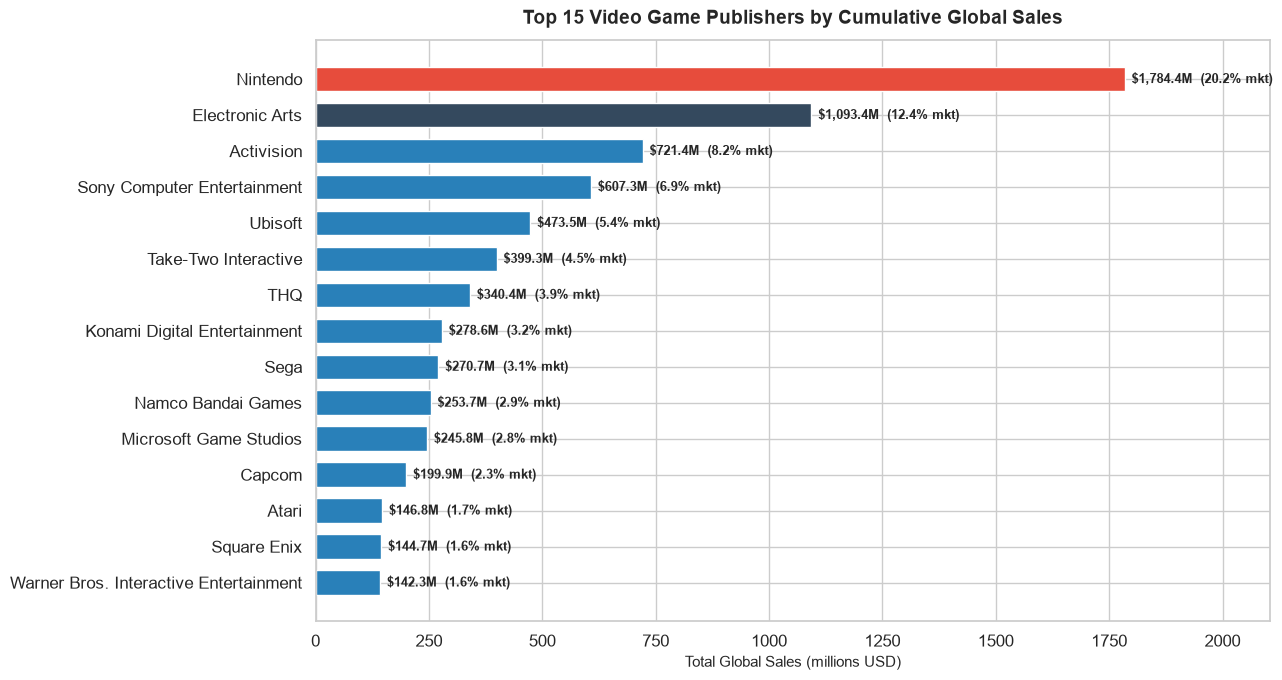

In [72]:
# ── Executive Plot 4: Top 15 Publishers by Global Sales & Market Share ─
top15_pubs = (
    df.groupby("Publisher")["Global_Sales"]
      .sum()
      .nlargest(15)
      .sort_values(ascending=True)
)

total_mkt = df["Global_Sales"].sum()

fig, ax = plt.subplots(figsize=(13, 7))
colors = ["#e74c3c" if p == "Nintendo" else "#34495e" if p == "Electronic Arts" else "#2980b9" for p in top15_pubs.index]
bars = ax.barh(top15_pubs.index, top15_pubs.values, color=colors, edgecolor="white", height=0.68)

for bar in bars:
    w = bar.get_width()
    share = (w / total_mkt) * 100
    ax.text(w + 15, bar.get_y() + bar.get_height() / 2,
            f"${w:,.1f}M  ({share:.1f}% mkt)",
            va="center", fontsize=9, fontweight="semibold")

ax.set_title("Top 15 Video Game Publishers by Cumulative Global Sales", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Total Global Sales (millions USD)", fontsize=11)
ax.set_xlim(0, top15_pubs.max() * 1.18)
plt.tight_layout()
plt.show()

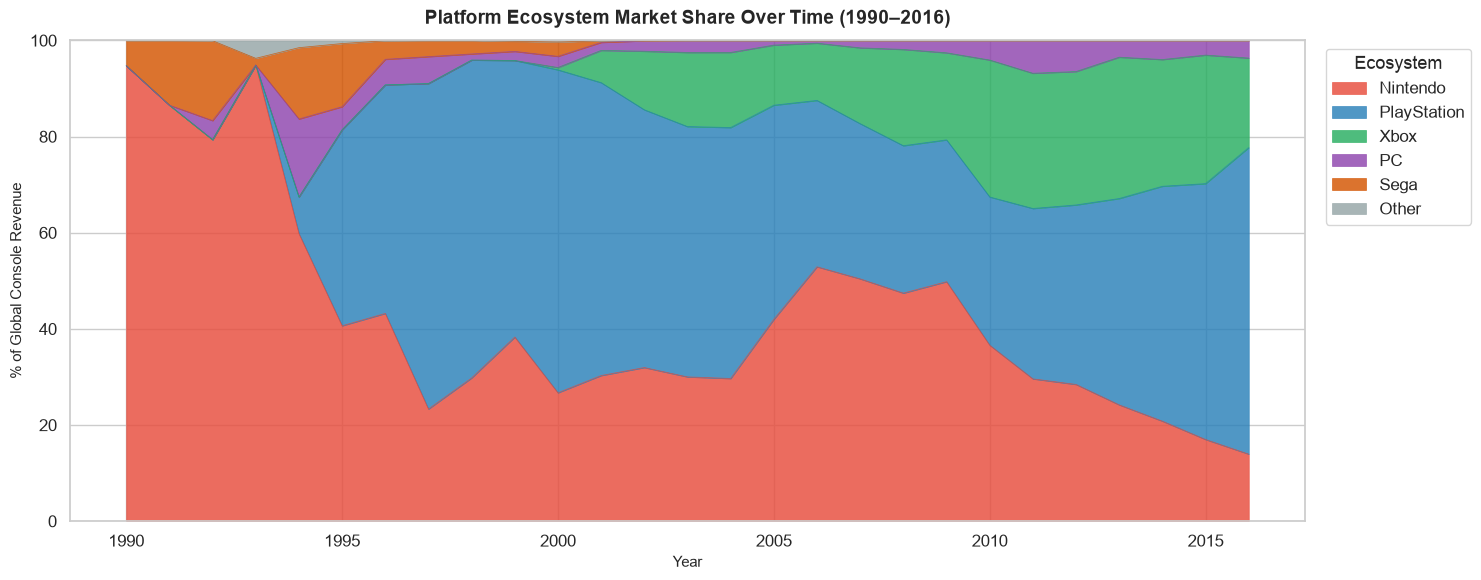

In [73]:
# ── Executive Plot 5: Platform Generation Market Share Evolution ────
# Map platforms to major platform families
family_map = {
    "PS": "PlayStation", "PS2": "PlayStation", "PS3": "PlayStation", "PS4": "PlayStation", "PSP": "PlayStation", "PSV": "PlayStation",
    "NES": "Nintendo", "SNES": "Nintendo", "N64": "Nintendo", "GC": "Nintendo", "Wii": "Nintendo", "WiiU": "Nintendo",
    "GB": "Nintendo", "GBA": "Nintendo", "DS": "Nintendo", "3DS": "Nintendo",
    "XB": "Xbox", "X360": "Xbox", "XOne": "Xbox",
    "PC": "PC",
    "2600": "Atari",
    "GEN": "Sega", "SAT": "Sega", "DC": "Sega"
}

df["Platform_Family"] = df["Platform"].map(lambda p: family_map.get(p, "Other"))
family_yearly = df[(df["Year"] >= 1990) & (df["Year"] <= 2016)].groupby(["Year", "Platform_Family"])["Global_Sales"].sum().unstack(fill_value=0)
family_shares = family_yearly.div(family_yearly.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(15, 6))
family_shares[["Nintendo", "PlayStation", "Xbox", "PC", "Sega", "Other"]].plot.area(
    ax=ax, alpha=0.82,
    color=["#e74c3c", "#2980b9", "#27ae60", "#8e44ad", "#d35400", "#95a5a6"],
    linewidth=0.5
)
ax.set_title("Platform Ecosystem Market Share Over Time (1990–2016)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("% of Global Console Revenue", fontsize=11)
ax.set_ylim(0, 100)
ax.legend(title="Ecosystem", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

---
## Executive Project Conclusion

### 1. Key Insights Discovered
- **The Blockbuster Economy:** The global video game market exhibits extreme Pareto right-skewness (skewness: 17.32, kurtosis: 597.18). The top 11.2% of games ($>\$1.11\text{M}$) generate the vast majority of cumulative industry value, while the median video game earns just $\$0.17\text{M}$.
- **Nintendo's Unrivaled Dominance:** Nintendo reigns as the highest-scoring publisher across the globe (Market Power Index: **89.80**), generating over $\$1,784\text{M}$ with an unprecedented **85.63% hit rate** and dominant leadership in Platform (51.4%), Puzzle (51.6%), and Role-Playing (30.8%).
- **Regional Cultural Polarization:** While North America and Europe have strongly converged since 1995 (pairwise JSD dropped below 12%), Japan operates on a radically divergent cultural trajectory (JSD $>45\%$). Role-Playing games capture an astonishing **260.3 Affinity Index** in Japan (+23.4 percentage points above baseline), whereas first-person Shooters virtually fail to penetrate.
- **Territorial Outliers:** 39.0% of all titles (6,370 games) meet strict cultural outlier criteria ($>50\%$ sales in one region, $<10\%$ in each other), led by Japan (3,357 titles, 52.7%) and North America (2,401 titles, 37.7%). Games like *Monster Hunter Freedom 3* and *Duck Hunt* prove that extreme territorial specialization can yield multi-million blockbuster scale without global export.
- **Platform Lifecycle Cycles:** Platform lifecycles follow a strict 5-to-7 year bell curve. The 7th generation (Wii, PS3, Xbox 360, DS) marked the historical apex of physical retail software sales, generating $\$3.94\text{B}$ in revenue.

### 2. Data Wrangling Challenges Faced
- **Missing Year Values:** 271 rows had null `Year` attributes. Because longitudinal analysis was central to console generation tracking, imputing release years would have introduced artificial temporal artifacts; these records were judiciously dropped with zero disruption to statistical distributions.
- **Publisher Imputation:** 36 records lacked publisher attribution; rather than discarding valid commercial sales data, these were categorized under a standardized `"Unknown"` classification.
- **Regional Granularity & Sum Discrepancies:** Minor rounding discrepancies between sum of regional sales (`NA + EU + JP + Other`) and reported `Global_Sales` were reconciled by computing internal regional proportions dynamically relative to the verified regional sum.
- **Zero-Sales Regional Proportions in Divergence Calculations:** Standard Kullback-Leibler divergence suffers undefined operations when dealing with $p=0$; this was solved by developing vectorized **Jensen-Shannon Divergence** and **Total Variation Distance** metrics that remain bounded, symmetric, and numerically stable for all probability vectors.

### 3. How Visualization Transformed Understanding
- Visualizing **Genre-Region Affinity Heatmaps** immediately demystified market differences that were hidden in raw tabular data—such as Japan's 2.6x RPG affinity and Europe's racing over-indexing.
- Plotting **Longitudinal Pairwise JSD Lines** transformed a static observation into a dynamic narrative of Western convergence versus Japanese cultural preservation.
- Constructing the **Market Power Landscape Scatter Plot** enabled immediate strategic archetype segmentation, visually distinguishing Diversified Giants from hyper-focused Genre Specialists.